# TFM — Análisis de clientes Olist (Brazilian E-Commerce)

##Pre-Indice 1. Montar drive, importar e instalar librerías necesarias

Se irá actualizando con cada librería que se requiera.

In [ ]:
# Montar drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import warnings
warnings.filterwarnings('ignore')

# Acceso a carpeta y carga del archivo de funciones
import sys
sys.path.append('/content/drive/MyDrive/TFM Trabajo')

Mounted at /content/drive


In [ ]:
!pip install shap

In [ ]:
!pip install feature-engine
!python -V

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 6.3 MB/s eta 0:00:00
Python 3.13.15


In [ ]:
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.2/44.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 68.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.2/132.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [ ]:
!pip install geopandas

In [ ]:
!pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.4 MB/s eta 0:00:00


In [ ]:
!pip install fastapi uvicorn joblib

In [ ]:
!pip install lightgbm

In [ ]:
# Instalamos en su lugar optbinning sin version dado que da problemas en este entorno la versión que conocemos
!pip install optbinning

INFO: pip is looking at multiple versions of optbinning to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.9/213.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 9.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requ

In [ ]:
# lo básico
import pandas as pd
import numpy as np
from Funciones import *

# visualización
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
%matplotlib inline

import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Geográfico
import geopandas as gpd

# pre procesado
from sklearn.model_selection import train_test_split
from ydata_profiling import ProfileReport
from sklearn.preprocessing import RobustScaler
import sklearn.impute as skl_imp
from sklearn.experimental import enable_iterative_imputer
import feature_engine.imputation as fe_imp
from statsmodels.formula.api import logit

#Análisis Estadístico
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.formula.api import ols
from scipy import stats

# modelado
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, scale
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.naive_bayes import GaussianNB

# Segmentación de clientes
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# métricas
from pandas.plotting import scatter_matrix
from sklearn.metrics import accuracy_score, roc_auc_score, auc, confusion_matrix, f1_score, precision_score, recall_score, roc_curve, classification_report, balanced_accuracy_score

# mejora de modelos
from sklearn.feature_selection import VarianceThreshold, SelectKBest
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from imblearn.over_sampling import SMOTE

# automatización
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

#Scoring
from optbinning import Scorecard, BinningProcess
from optbinning.scorecard import plot_auc_roc, plot_ks, plot_cap

#Pre procesado
from fastapi import FastAPI
from pydantic import BaseModel
from typing import Literal
import pandas as pd
import pickle
import uvicorn
import threading
import requests
import ipywidgets as widgets

#Otros
import requests
import re
from datetime import datetime
from bs4 import BeautifulSoup
import glob
from google.colab import files
import gc

import pickle
import mlflow
import joblib
from IPython.display import Image, display

#Interpretabilidad
import shap

sns.set()
get_ipython().run_line_magic('matplotlib', 'inline')

(CVXPY) Sep 12 03:07:03 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Sep 12 03:07:03 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Sep 12 03:07:03 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Sep 12 03:07:03 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


##2. Descripción del dataset

###2.1 Arquitectura relacional (Carga de los datasets)

Siguiendo el esquema de los datos (abajo) se importan todos los dataset y se establece orders como el punto central de todos.


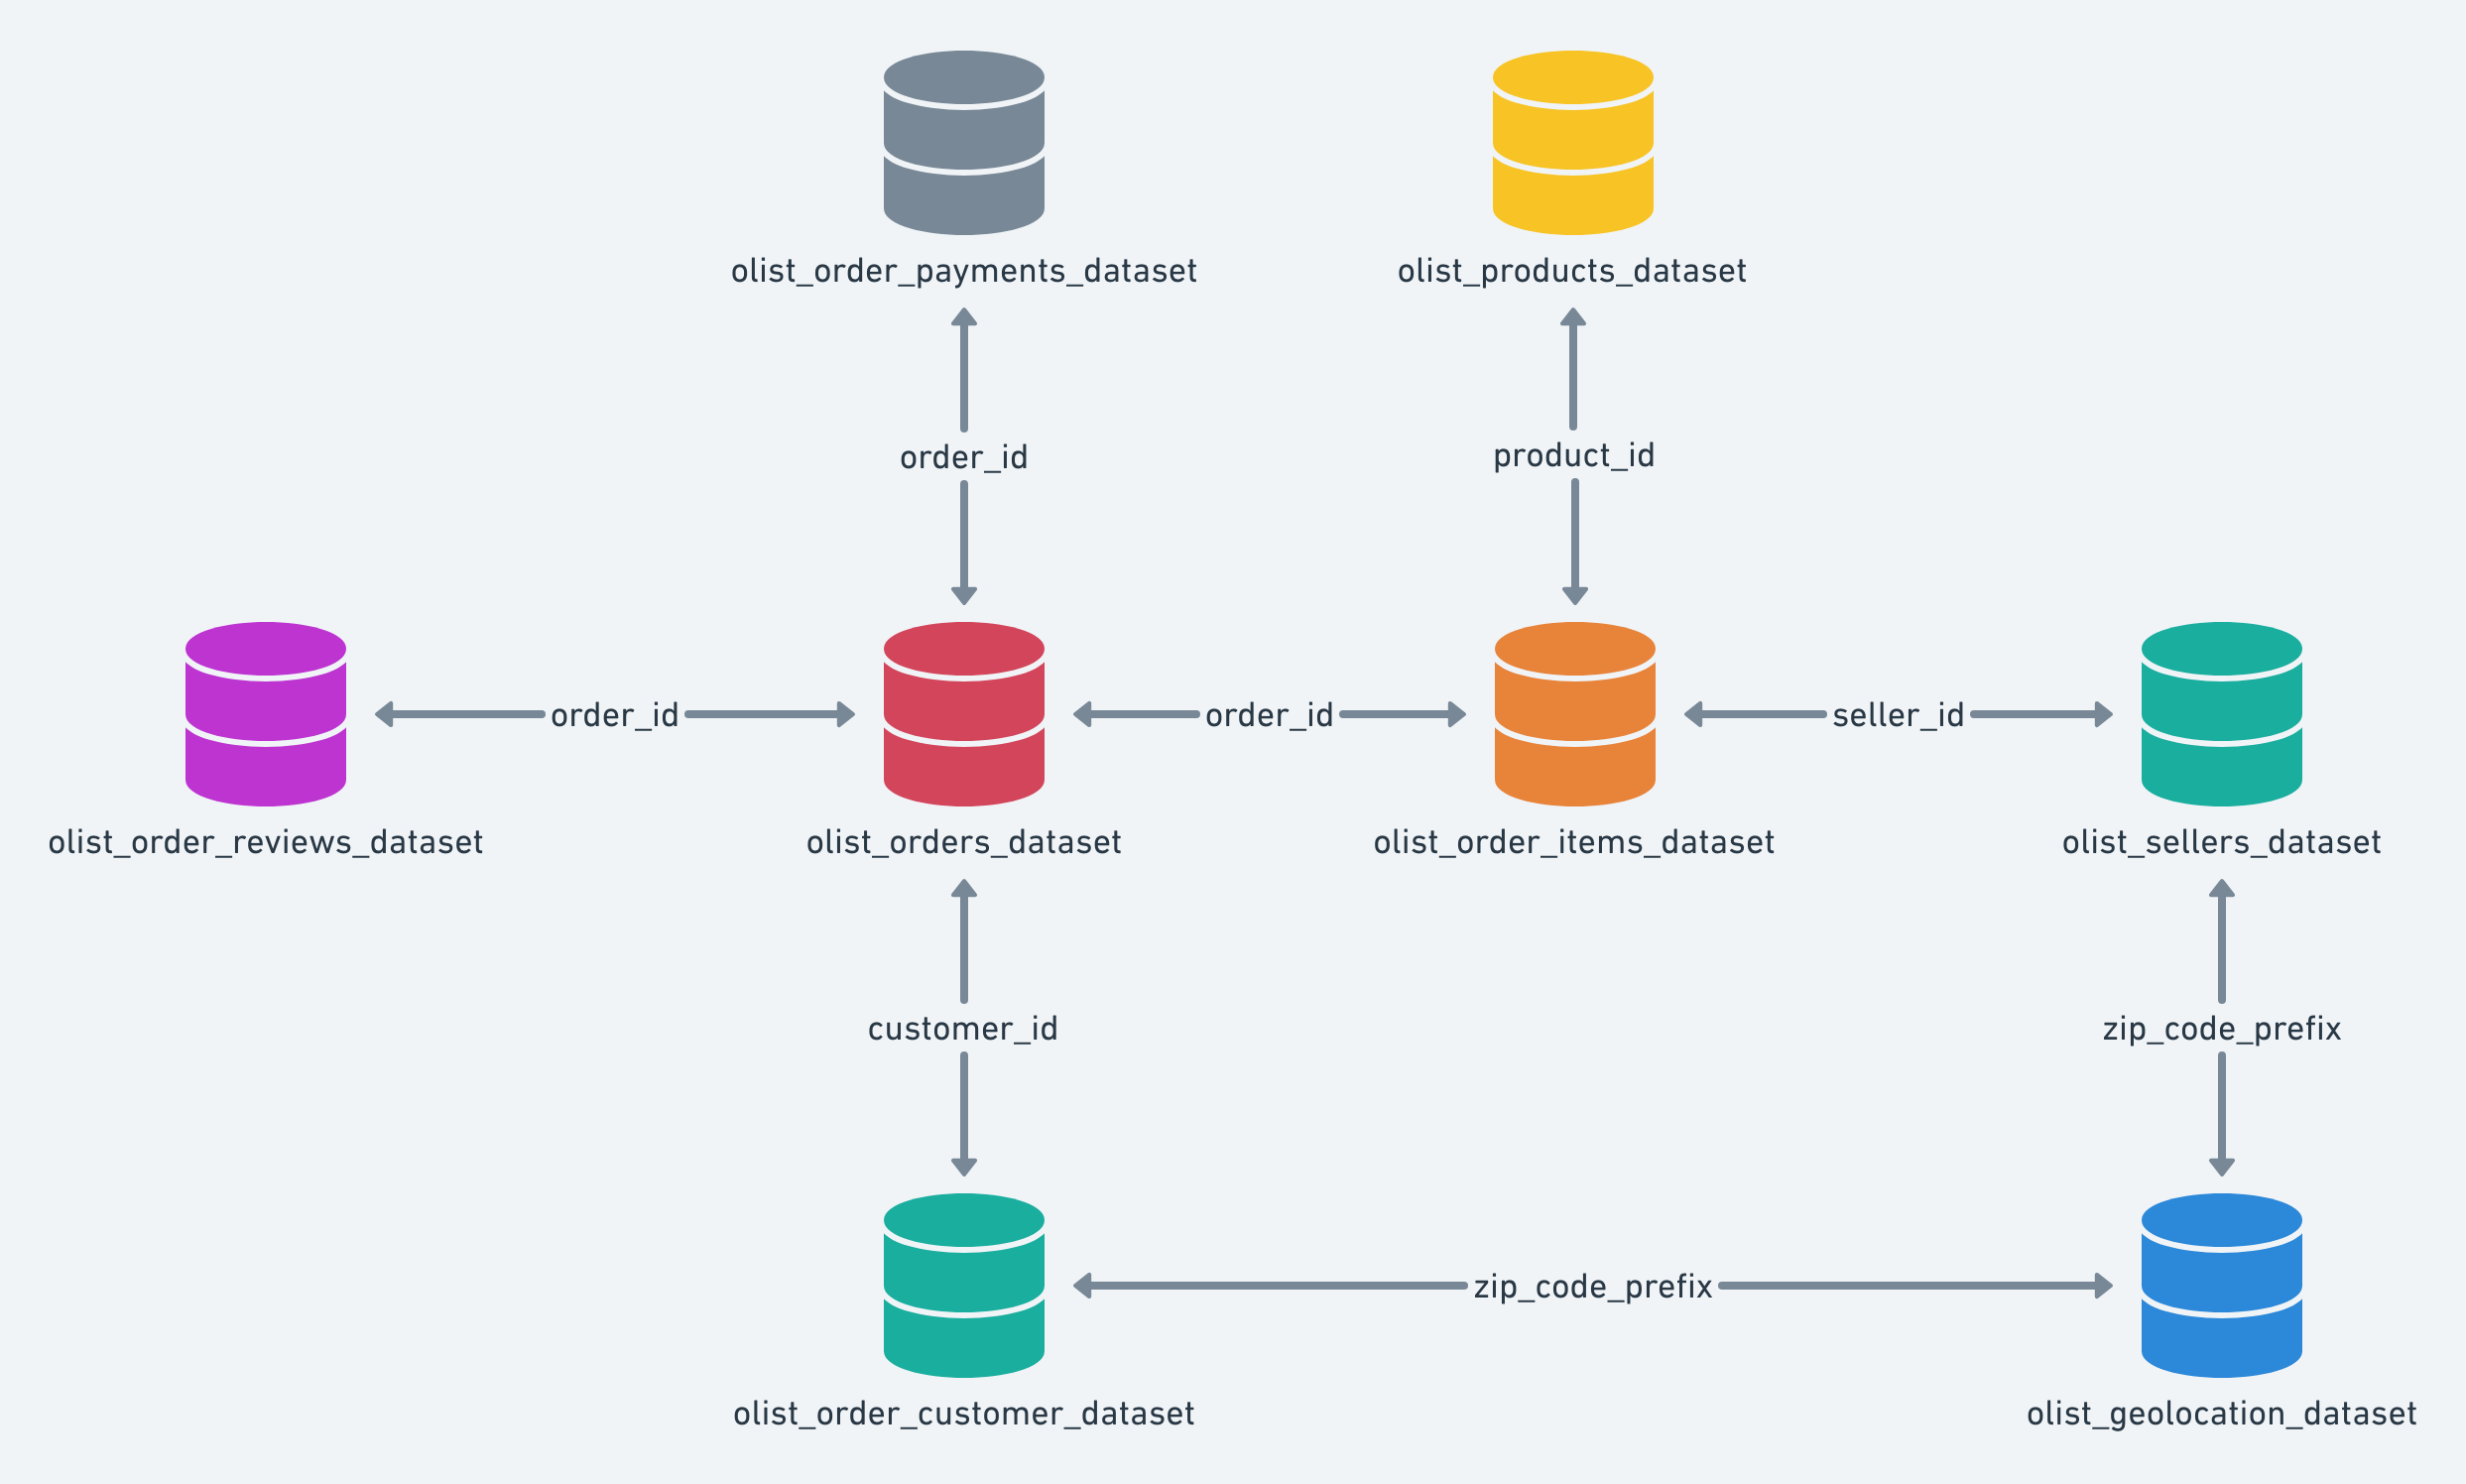

In [ ]:
display(Image(filename="/content/drive/MyDrive/TFM Trabajo/Esquema datasets.png",width=600))

In [ ]:
orders = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_orders_dataset.csv",
                     parse_dates=['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date','order_delivered_customer_date', 'order_estimated_delivery_date']
)

customers = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_customers_dataset.csv")

order_items = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_order_items_dataset.csv",
                          parse_dates=['shipping_limit_date'])

order_payments = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_order_payments_dataset.csv")


order_reviews = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_order_reviews_dataset.csv",
                            parse_dates=['review_creation_date', 'review_answer_timestamp'])

products = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_products_dataset.csv")

sellers = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_sellers_dataset.csv")

cat_translation = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/product_category_name_translation.csv")

geolocation = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/Dataset_Brazilian_ECommerce_Olist/olist_geolocation_dataset.csv")

print('orders:', orders.shape)
print('customers:', customers.shape)
print('order_items:', order_items.shape)
print('order_payments:', order_payments.shape)
print('order_reviews:', order_reviews.shape)
print('products:', products.shape)
print('sellers:', sellers.shape)
print('cat_translation:', cat_translation.shape)
print('geolocation:', geolocation.shape)

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
order_payments: (103886, 5)
order_reviews: (99224, 7)
products: (32951, 9)
sellers: (3095, 4)
cat_translation: (71, 2)
geolocation: (1000163, 5)


In [ ]:
#Los unimos en datasets para poder gestionar todos los df de forma conjunta si es necesario
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": order_payments,
    "Reviews": order_reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": cat_translation
}

##2. Descripción del dataset

###2.2 Diccionario de variables disponibles
###2.3. Calidad y limitaciones de datos

En primer lugar, hacemos un repaso rápido de todos los dataset y creamos una funcion para poder aplicar cambios a todos. Buscamos:

1. Tipos de variables
2. Valores mal codificados
3. Valores fuera de rango
4. Variables nominales o Factores con categorías minoritarias

Después, observaremos tanto los Outliers como los Missings.

###ProfileReport

In [ ]:
for name, df in datasets.items():
    profile = ProfileReport(df, title=f"Profiling - {name}")
    profile.to_file(f"profiling_{name.replace(' ', '_')}.html")
    filename = f"profiling_{name.replace(' ', '_')}.html"
    profile.to_file(filename)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:06<00:00,  1.23s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

...


100%|██████████| 2/2 [00:00<00:00, 67.62it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
#for file in glob.glob("profiling_*.html"):
 #   files.download(file)

Notas del profiling
- Sellers
  - seller_state está altamente correlacionado con seller_zip_code_prefix.
  - La mayoría de los vendedores son de SP.
  - Revisar la relación entre seller_state y seller_zip_code_prefix.
  - Hacer wordcloud de seller_city.

-  Category Translation
  - Hacer wordcloud de las categorías de producto para ver cuáles son las más frecuentes

- Customers
  - customer_state is highly overall correlated with customer_zip_code_prefix
  - customer_zip_code_prefix is highly overall correlated with customer_state
  - customer_city wordcloud
  - customer_state most from SP

- Geolocation
  - Dataset has 128174 (12.8%) duplicate rows
  - Correlation among state, lat, zip code, state
  - geolocation_city wordcloud
  - geolocation_state most from SP

- Order_Items
  - histograma order_item_id nº
  - shipping_limit_date ver outliers + histograma
  - price ver outliers + histograma
  - freight_value ver outliers + histograma
- Orders
  - order_status is highly imbalanced (91.4%)
  - order_delivered_carrier_date has 1783 (1.8%) missing values
  - order_delivered_customer_date has 2965 (3.0%) missing values
  - Picos en order_approved_at, order_delivered_carrier_date y order_purchase_timestamp histograma
- Payments
  - payment_sequential outliers + histograma
  - payment_installments outliers + histograma
  - payment_value outliers + histograma
Products
  - Correlation among size columns
  - missing en size columns
Reviews
  - review_comment_title has 87656 (88.3%) missing values
  - review_comment_message has 58247 (58.7%) missing values
OBSERVACIONES GENERALES DEL PROFILING

1. Hay correlación entre los códigos postales y los estados tanto en `CUSTOMERS` como en `SELLERS`.
2. `SP` es el estado con más clientes, vendedores y registros de geolocalización.
3. `GEOLOCATION` tiene bastantes duplicados (12,8%), por lo que hay que comprobar si son duplicados reales o registros de la misma localización.
4. `ORDERS` está muy desbalanceado en `order_status`, con mayoría de pedidos `delivered`.
5. Hay algunos missing en las fechas de entrega de `ORDERS` que habrá que revisar antes de decidir cómo tratarlos.
6. `REVIEWS` tiene muchos missing en los campos de comentarios, pero son campos opcionales y no necesariamente un problema de calidad.
7. En `ORDER ITEMS` hay que revisar la distribución y outliers de `price` y `freight_value`.
8. En `PAYMENTS` hay que revisar la distribución y outliers de `payment_sequential`, `payment_installments` y `payment_value`.
9. En `PRODUCTS` hay que revisar la correlación entre las variables de tamaño y sus missing.
10. Las categorías de productos se pueden analizar utilizando `Category Translation` para tener también los nombres en inglés.
11. Los datos de clientes, vendedores y geolocalización permiten hacer posteriormente análisis por estado y ciudad.

###Overview de los datos
Analizamos claves y problemas de los datasets
- CUSTOMERS

Claves: 99.441 clientes y 5 columnas, valores normales, tipos de datos normales, no missing, no duplicate. Tiene info de localización y el customer ID.

Problemas: Podemos convertir customer_zip_code_prefix a string para conservar ceros iniciales.

- ORDERS

Claves: 99.441 ordenes (1 por cliente) con order_ID unico. valores normales, tipos dato normales, no duplicate.

Problemas:  tiene nulos en order_approved_at	160, order_delivered_carrier_date	1783, order_delivered_customer_date	2965. Convertir a datetime las columnas de datos temporales (lo hacemos arriba).

- ORDER ITEMS

Claves: 112.650 items, valores normales, tipos dato normales, no missing, no duplicate

Problemas: convertir shipping_limit_date a datos temporales (lo hacemos arriba).

- PAYMENTS

Claves: 103.886 pagos, valores normales, tipos dato normales, no missing, no duplicate. Hay mas pagos que ordenes, por lo que algunas se han hecho con pago diferido.

Problemas: No problemas

- REVIEWS

Claves: 99.224 opiniones, valores normales, no duplicate

Problemas: de review_creation_date	y review_answer_timestamp a datos temporales (lo hacemos arriba).
Hay missing en review_comment_title	y review_comment_message (opcionales, es normal, no un error).

- PRODUCTS

Claves: 32.951 productos, valores normales, tipos dato normales, no duplicate

Problemas: product_category_name, product_name_lenght y product_description_lenght, product_photos_qty contienen missing.
product_name_lenght, product_description_lenght, product_photos_qty deberian ser int64.

- SELLERS

Claves: 3.095 vendedores, valores normales, tipos dato normales, no missing, no duplicate

Problemas: No problemas

- GEOLOCATION

Claves: 1.000.163 datos (el mas grande) valores normales, tipos dato normales, no missing,

Problemas:  duplicate pero es logico (mismas ciudades). Se comprobará

- CATEGORY TRANSLATION
Claves: 71 categorias, valores normales, tipos dato normales, no missing, no duplicate

Problemas: No problemas

OBSERVACIONES GENERALES:
1. 9 Tablas relacionadas entre si
2. Tabla ORDERS es el nucleo que relaciona CUSTOMERS, PRODUCTS, SELLERS, PAYMENTS, REVIEWS.
3. Casi todas las tablas están limpias con algunos problemas de calidad
4. Se puedem analizar datos temporales, se convierten a timestamp las columnas pertinentes
5. Gestionar los missing en ORDERS y PRODUCTS, en REVIEW se mantienen
6. Unir tablas y comprobar relaciones
7. Ha que revisar los duplicados de geolocation

OPCIONALES (SI DA TIEMPO)
1. Comparar Zip code con Customer state y city
2. Separar horas y dias para analizar por separado
3. GEOLOCATION que esten dentro de Brasil los valores
4. Product cat name a ver si la podemos sustituir directamente por English

In [ ]:
#Antes de analizarlos uno a uno, vemos su forma rapidamente
for name, df in datasets.items():
    print(name, df.shape)

Customers (99441, 5)
Orders (99441, 8)
Order Items (112650, 7)
Payments (103886, 5)
Reviews (99224, 7)
Products (32951, 9)
Sellers (3095, 4)
Geolocation (1000163, 5)
Category Translation (71, 2)


In [ ]:
#Como son muy diferentes, los vamos a anlizar grupalmente en una tabla
overview = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()],
    "Missing Values": [df.isnull().sum().sum() for df in datasets.values()],
    "Duplicate Rows": [df.duplicated().sum() for df in datasets.values()]
})

overview


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Customers,99441,5,0,0
1,Orders,99441,8,4908,0
2,Order Items,112650,7,0,0
3,Payments,103886,5,0,0
4,Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Sellers,3095,4,0,0
7,Geolocation,1000163,5,0,261831
8,Category Translation,71,2,0,0


In [ ]:
#Para todos los dataset, vemos nulos, duplicados ,tipo de dato y las primeras filas para ver si hay algo raro
for name, df in datasets.items():
    print("="*80)
    print(f"{name.upper()}")
    print("="*80)

    print("\nShape:")
    print(df.shape)

    print("\nFirst 10 Rows:")
    display(df.head(10))

    print("\nData Types:")
    display(df.dtypes)

    print("\nMissing Values:")
    display(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

CUSTOMERS

Shape:
(99441, 5)

First 10 Rows:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG



Data Types:


,0
customer_id,object
customer_unique_id,object
customer_zip_code_prefix,int64
customer_city,object
customer_state,object



Missing Values:


...


Data Types:


,0
product_category_name,object
product_category_name_english,object



Missing Values:


,0
product_category_name,0
product_category_name_english,0



Duplicate Rows:
0


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.nunique())


Customers


,0
customer_id,99441
customer_unique_id,96096
customer_zip_code_prefix,14994
customer_city,4119
customer_state,27



Orders


,0
order_id,99441
customer_id,99441
order_status,8
order_purchase_timestamp,98875
order_approved_at,90733
order_delivered_carrier_date,81018
order_delivered_customer_date,95664
order_estimated_delivery_date,459



Order Items


...

,0
seller_id,3095
seller_zip_code_prefix,2246
seller_city,611
seller_state,23



Geolocation


,0
geolocation_zip_code_prefix,19015
geolocation_lat,717360
geolocation_lng,717613
geolocation_city,8011
geolocation_state,27



Category Translation


,0
product_category_name,71
product_category_name_english,71


Resumen de datos unicos
Analizamos claves y problemas de los datasets
- CUSTOMERS
  - 1 dato por cada compra (customer_id)
  - customer_unique_id muestra menos datos, hay compradores con mas de una compra
  - Compras en 4.119 ciudades de 27 estados

- ORDERS
  - 1 dato por cada orden (order_id)
  - 8 estados diferentes para el proceso de ordenes
  - Casi todas las ordenes han sido entregadas a comprador,
  - Algunos carrier llevan varias ordenes a la vez los mismos dias

- ORDER ITEMS
  - Hay mas ordenes hechas que items comprados,
  - 21 order_item_id son pocos tipos, no se que significa
  - Hay 32.951 tipos de productos diferentes

- PAYMENTS
  - 5 formas de pago
  - Hasta en 24 mensualidades
  - payment_sequential no se que significa
  - Casi todas las ordenes con algun tipo de dato de pago

- REVIEWS
  - Sistema de Puntuacion de 1 a 5
  - casi todas las compras tienen review
  - Casi ninguna tiene titulo, pocas tienen mensaje
  - Casi todas las review se responden

- PRODUCTS
  - Hay 32.951 tipos de productos diferentes, confirmado
  - 73 categorias de producto
  - Variedad de descripcion y tamaño de productos

- SELLERS
  - 3.095 vendedores, confirmado
  - Vendedores de 611 ciudades de 23 estados, mucho mas concentrado que compras

- GEOLOCATION
  - Hasta 8.011 ciudades de 27 estados, muchas ciudades para tan pocas ciudades de vendedores
  - Los valores de latitud y longitud son muy diversos, lo que respalda el análisis geográfico.

- CATEGORY TRANSLATION
  - 71 categorias con traduccion, hay 2 no traducidas

In [ ]:
missing_summary = []

for name, df in datasets.items():
    for col in df.columns:
        missing = df[col].isna().sum()
        percentage = df[col].isna().mean() * 100

        if missing > 0:
            missing_summary.append({
                "Dataset": name,
                "Variable": col,
                "Missing": missing,
                "Missing %": round(percentage, 2)
            })

missing_summary = pd.DataFrame(missing_summary)

missing_summary = missing_summary.sort_values(
    "Missing %",
    ascending=False
).reset_index(drop=True)

display(missing_summary)

,Dataset,Variable,Missing,Missing %
0,Reviews,review_comment_title,87656,88.34
1,Reviews,review_comment_message,58247,58.70
2,Orders,order_delivered_customer_date,2965,2.98
3,Products,product_name_lenght,610,1.85
4,Products,product_category_name,610,1.85
5,Products,product_description_lenght,610,1.85
6,Products,product_photos_qty,610,1.85
7,Orders,order_delivered_carrier_date,1783,1.79
8,Orders,order_approved_at,160,0.16
9,Products,product_weight_g,2,0.01


Analisis de Missings
- apenas hay columnas con missings
- review_comment_title y review_comment_message seran eliminados
- Los missing de products y orders se gestionaran posteriormente en la limpieza

###Analisis Columnas numericas y categoricas

In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.describe())


Customers


,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000



Orders


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99281,97658,96476,99441
mean,2017-12-31 08:43:12.776581120,2017-12-31 18:35:24.098800128,2018-01-04 21:49:48.138278656,2018-01-14 12:09:19.035542272,2018-01-24 03:08:37.730111232
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.249999872,2017-09-25 22:07:22.249999872,2017-10-03 00:00:00
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.249999872,2018-05-25 00:00:00
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00



Order Items


...

,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000



Geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02



Category Translation


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


Analisis de variables numericas
Analizamos claves y problemas de los datasets
- CUSTOMERS
  - Nada que reseñar

- ORDERS
  - Solo los missing en order_approved_at, order_delivered_carrier_date, order_delivered_customer_date son relevantes.

- ORDER ITEMS
  - Price parece tener outliers a la derecha (max es 6.735 siendo media y 50% 120.65 y 74.99, respectivamente).
  - freight_value parece tener outliers a la derecha (max es 409 siendo media y 50% 19.99 y 716.26, respectivamente).

- PAYMENTS
  - La mayoria de payments son unicos, como ya se vio antes.
  - payment_value parece tener outliers a la derecha (max es 13.664 siendo media y 50% 154.1 y 100, respectivamente).

- REVIEWS
  - Interesante que la media de puntuación es 4, y apenas un 25% estan por debajo de ese valor

- PRODUCTS
  - Estan los missing ya identificados previamente
  - Hay algunos valores máximos (peso, cantidad de fotos y tamaño) que se desvían de los demás. O son outliers o (mas probablemente) algún artículo especialmente grande. Quizá coincida con aquellos posibles outliers de precio y valor de carga, y no sean outliers sino el coste de artículos muy grandes y caros.


- SELLERS, GEOLOCATION, CATEGORY TRANSLATION
  - Nada que reseñar


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.describe(include="object"))


Customers


,customer_id,customer_unique_id,customer_city,customer_state
count,99441,99441,99441,99441
unique,99441,96096,4119,27
top,274fa6071e5e17fe303b9748641082c8,8d50f5eadf50201ccdcedfb9e2ac8455,sao paulo,SP
freq,1,17,15540,41746



Orders


,order_id,customer_id,order_status
count,99441,99441,99441
unique,99441,99441,8
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered
freq,1,1,96478



Order Items


...

,seller_id,seller_city,seller_state
count,3095,3095,3095
unique,3095,611,23
top,9e25199f6ef7e7c347120ff175652c3b,sao paulo,SP
freq,1,694,1849



Geolocation


,geolocation_city,geolocation_state
count,1000163,1000163
unique,8011,27
top,sao paulo,SP
freq,135800,404268



Category Translation


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


Analisis de variables categóricas
Analizamos claves y problemas de los datasets
- CUSTOMERS
  - Hay compradores que hacen más de 1 compra separada

- ORDERS
  - Nada que reseñar

- ORDER ITEMS
  - Nada que reseñar

- PAYMENTS
  - Sobre todo pagos con credit_card

- REVIEWS
  - Priman las buenas recomendaciones

- PRODUCTS
  - Nada que reseñar

- SELLERS, GEOLOCATION, CATEGORY TRANSLATION
  - Nada que reseñar

In [ ]:
#Coinvertimos en categorica la variable de review_score y la ordenamos
order_reviews["review_score"] = order_reviews["review_score"].astype("category")

order_reviews.review_score.value_counts(sort=False)

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


##3. Construcción del dataset analítico

###3.1. Limpieza del dato y tratamiento de valores ausentes
En primer lugar vamos a eliminar las columnas con muchos missing que vimos anteriormente: review_comment_title y review_comment_message

En segundo lugar, eliminaremos los duplicados de geolocation.

En tercer lugar, convertimos en string las columnas con los datos del zip code para conservar los ceros iniciales.

En cuarto lugar, pasamos todas las columnas temporales a formato datetime

En quinto lugar, pasaremos a la gestión de outliers correspondiente. Para ello, en primer lugar hacemos un análisis visual de outliers, mediante boxplot e histogramas de todas las columnas.

Por último, gestionaremos los missing restantes, tanto de posibles outliers que convirtamos en missing, como de los DF ya vistos anteriormente de:

- ORDERS: order_approved_at, order_delivered_carrier_date ,order_delivered_customer_date,
- REVIEWS (ya eliminadas esas columnas)
- PRODUCTS: product_category_name, product_name_lenght,   product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm

####1. Eliminamos las columnas con más del 50% de missing

Estas columnas no son útiles para obtener información, por lo que se eliminan

In [ ]:
#1. Eliminamos las columnas con muchos missing
order_reviews.drop(
    columns=["review_comment_title", "review_comment_message"],
    inplace=True
)

order_reviews.head()

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01,2018-03-02 10:26:53


####2. Eliminamos los duplicados de geolocation

El DF de geolocation tiene muchos valores duplicados, que decidimos eliminar.

In [ ]:
geolocation.drop_duplicates(inplace=True)

print("Duplicados restantes:", geolocation.duplicated().sum())

Duplicados restantes: 0


####3. Corregimos las columnas de datos zip_code

Estas columnas deberían convertirse a string para conservar ceros iniciales. Son customer_zip_code_prefix, seller_zip_code_prefix y
geolocation_zip_code_prefix

In [ ]:
zip_cols = {
    'Customers': 'customer_zip_code_prefix',
    'Sellers': 'seller_zip_code_prefix',
    'Geolocation': 'geolocation_zip_code_prefix'
}

for dataset, col in zip_cols.items():
    datasets[dataset][col] = (
        datasets[dataset][col]
        .astype('string')
        .str.zfill(5)
    )

####4. Corregimos las columnas de datos temporales

Estas columnas cuentan con un tipo de dato incorrecto, que corregimos con to_datetime


In [ ]:
date_columns = {
    'Orders': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date'],
    'Order Items': ['shipping_limit_date'],
    'Reviews': ['review_creation_date', 'review_answer_timestamp']
}

for df_name, cols in date_columns.items():
    df = datasets[df_name]
    for col in cols:
        df[col] = pd.to_datetime(df[col], errors='coerce')
    print(f"\n{df_name}")
    display(df[cols].dtypes)


Orders


,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]



Order Items


,0
shipping_limit_date,datetime64[ns]



Reviews


,0
review_creation_date,datetime64[ns]
review_answer_timestamp,datetime64[ns]


####5. Analisis visual para detectar y gestionar outliers percibidos con anterioridad

Para ello, primero introducimos una función para crear un histograma y boxplot para todos los items de los datasets. Asi podremos analizar de forma visual tanto las columnas categóricas como las numéricas. La formula es histogram_boxplot.

Así con una sola fórmula, analizamos todas las columnas numericas del dataset de forma gráfica (histograma + boxplots), para a continuación analizar si hay outliers y si habria que hacer algo con ellos (winsorize, tratarlos como missing, etc)


In [ ]:
## Función para histograma con boxplot
def histogram_boxplot(data, xlabel = None, title = None, font_scale=2, figsize=(9,8), bins = None):
    """ Boxplot and histogram combined
    data: 1-d data array
    xlabel: xlabel
    title: title
    font_scale: the scale of the font (default 2)
    figsize: size of fig (default (9,8))
    bins: number of bins (default None / auto)

    example use: histogram_boxplot(np.random.rand(100), bins = 20, title="Fancy plot")
    """
    # Definir tamaño letra
    sns.set(font_scale=font_scale)
    # Crear ventana para los subgráficos
    f2, (ax_box2, ax_hist2) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)}, figsize=figsize)
    # Crear boxplot
    sns.boxplot(x=data, ax=ax_box2)
    # Crear histograma
    sns.histplot(x=data, ax=ax_hist2, bins=bins) if bins else sns.histplot(x=data, ax=ax_hist2)
    # Pintar una línea con la media
    ax_hist2.axvline(np.mean(data),color='g',linestyle='-')
    # Pintar una línea con la mediana
    ax_hist2.axvline(np.median(data),color='y',linestyle='--')
    # Asignar título y nombre de eje si tal
    if xlabel: ax_hist2.set(xlabel=xlabel)
    if title: ax_box2.set(title=title, xlabel="")
    # Mostrar gráfico
    plt.show()

CUSTOMERS
ORDERS
ORDER ITEMS


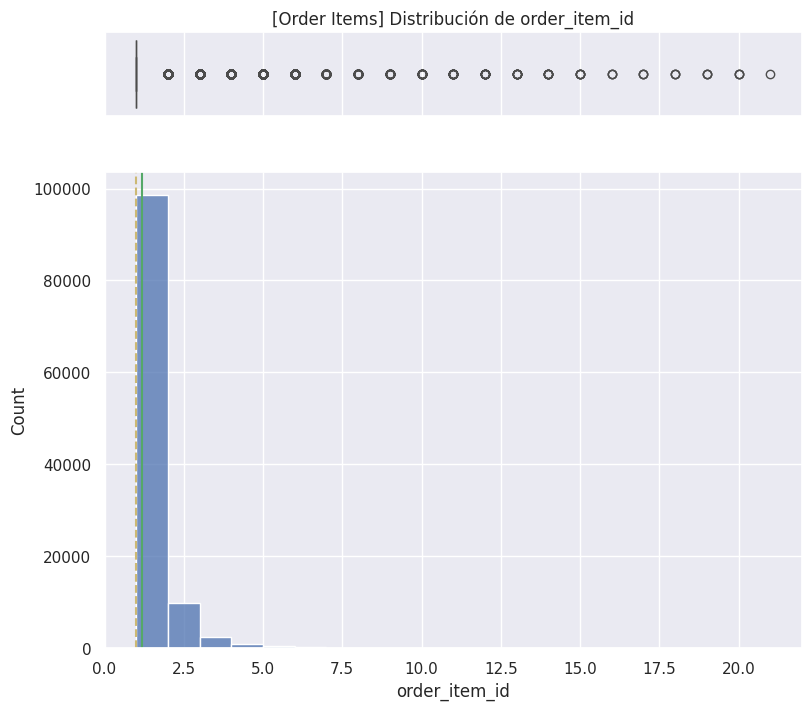

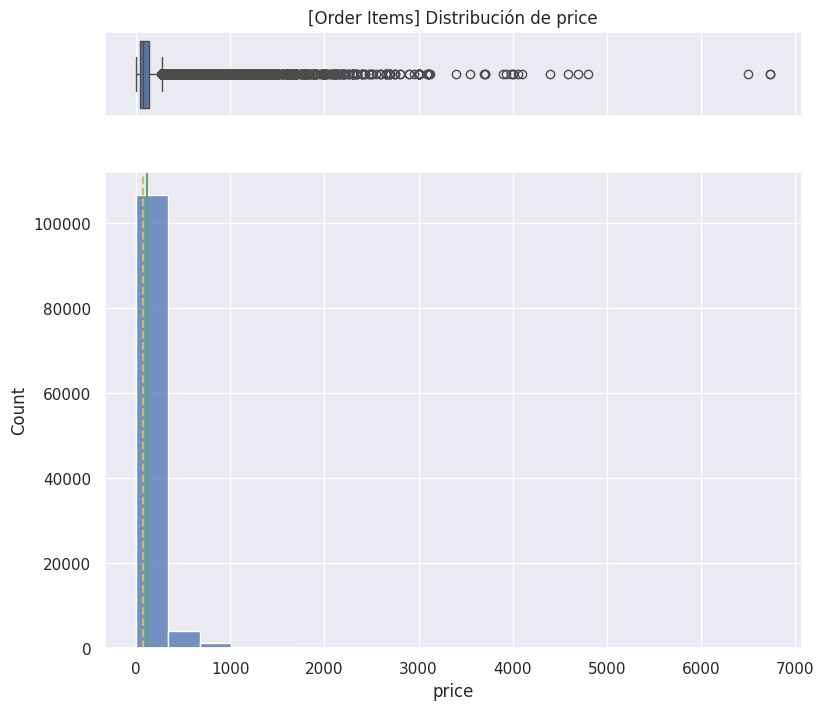

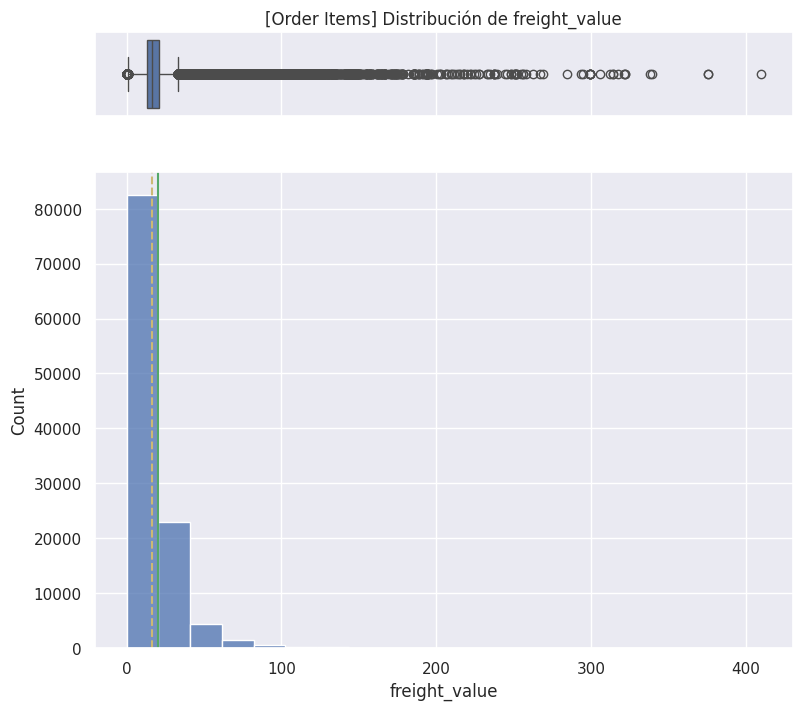

PAYMENTS


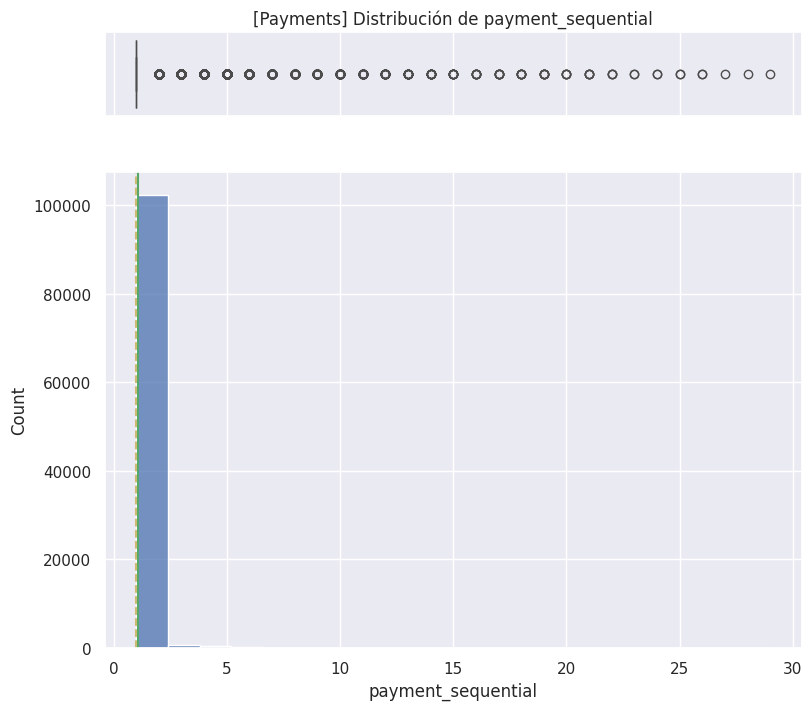

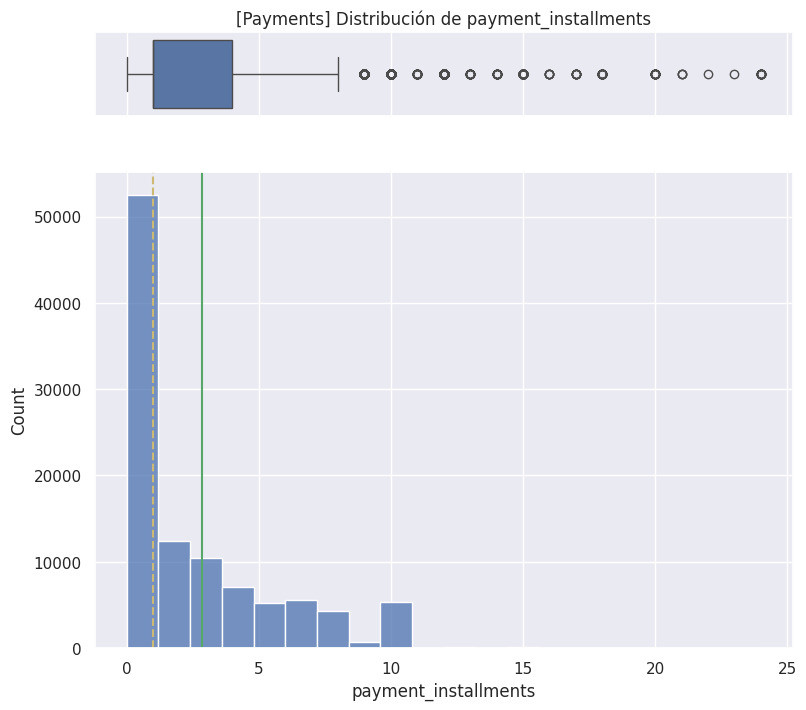

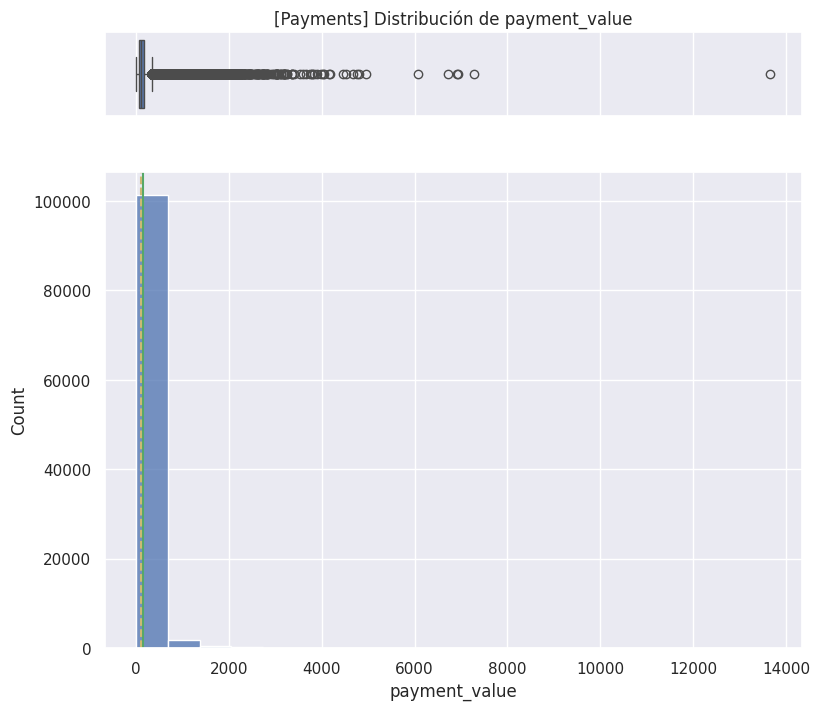

REVIEWS
PRODUCTS


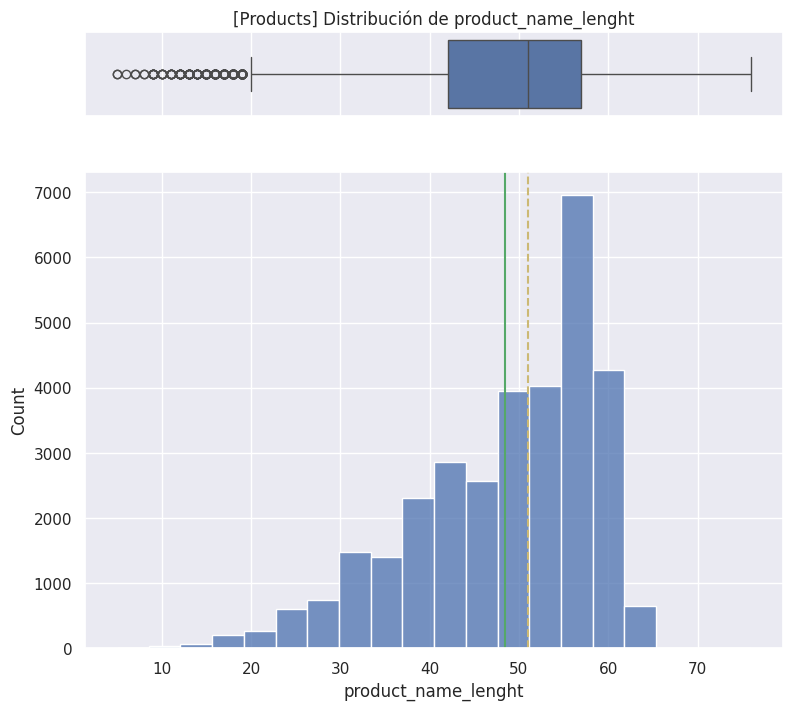

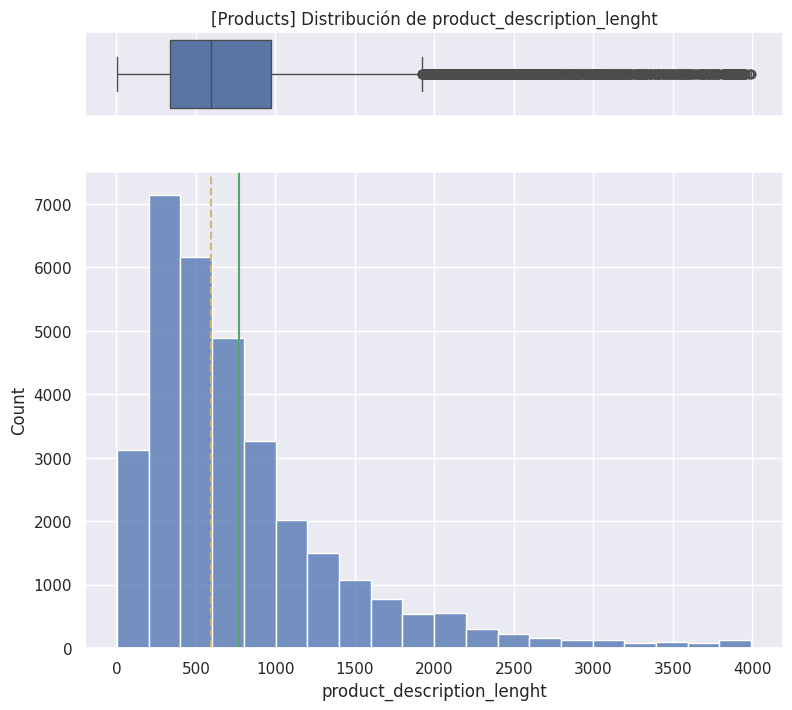

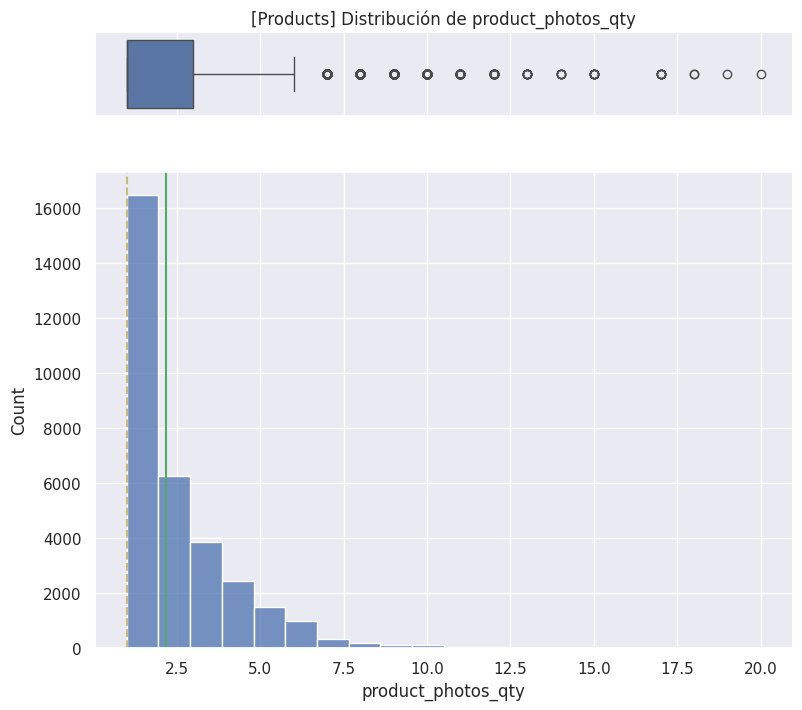

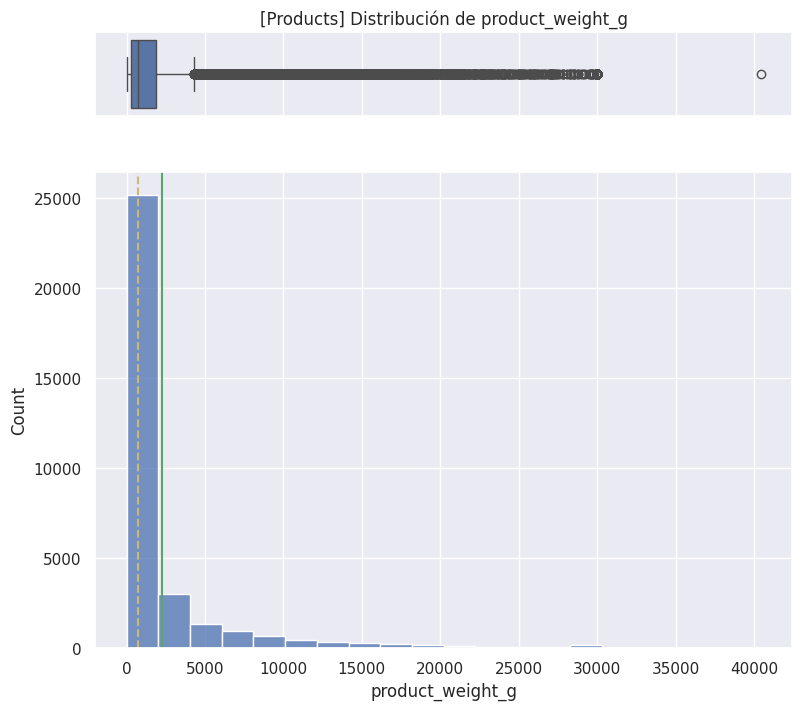

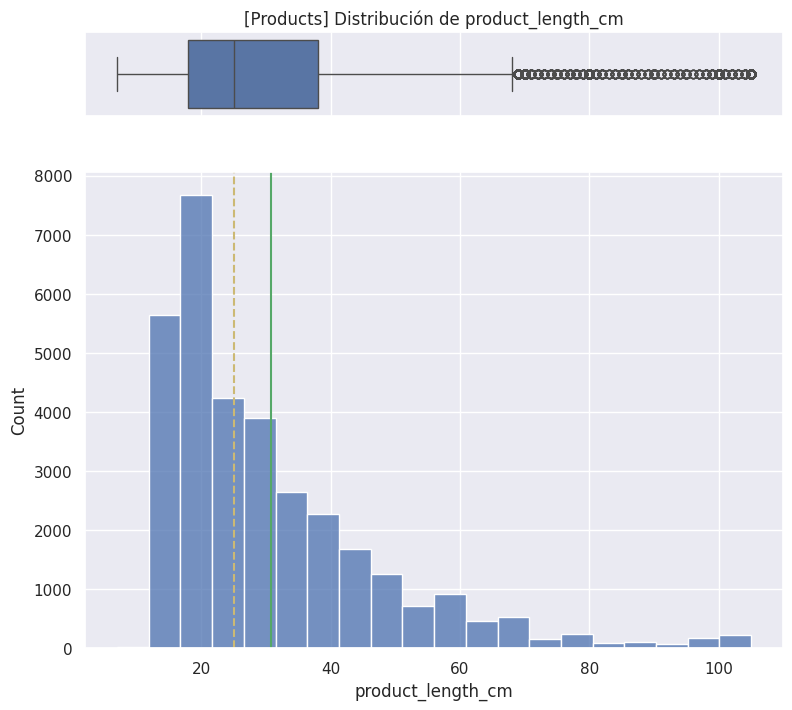

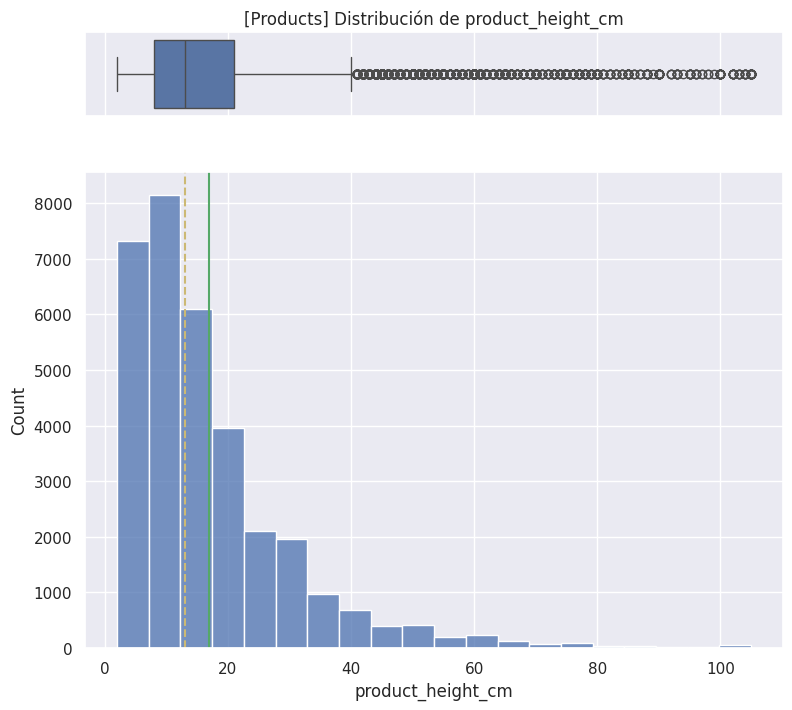

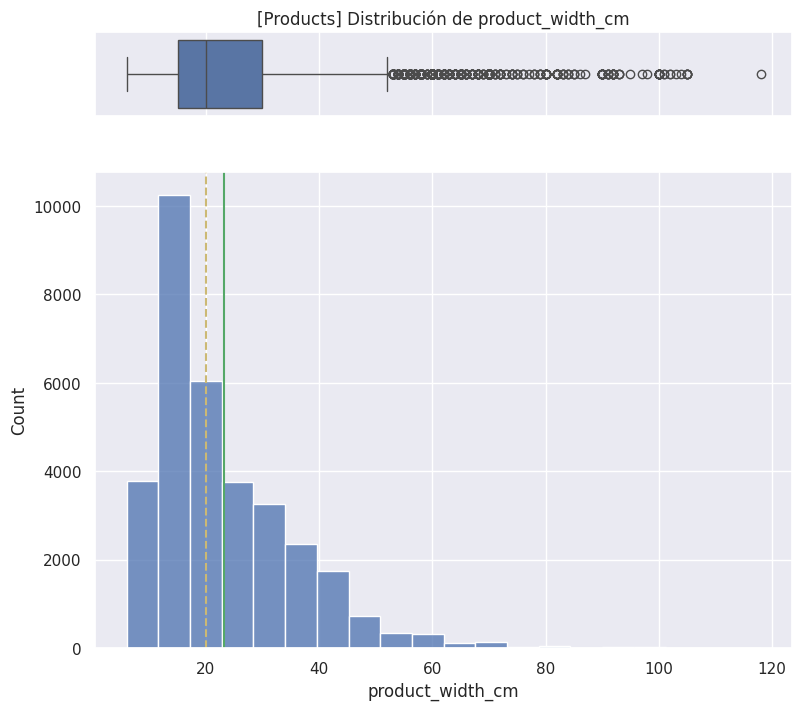

SELLERS
GEOLOCATION


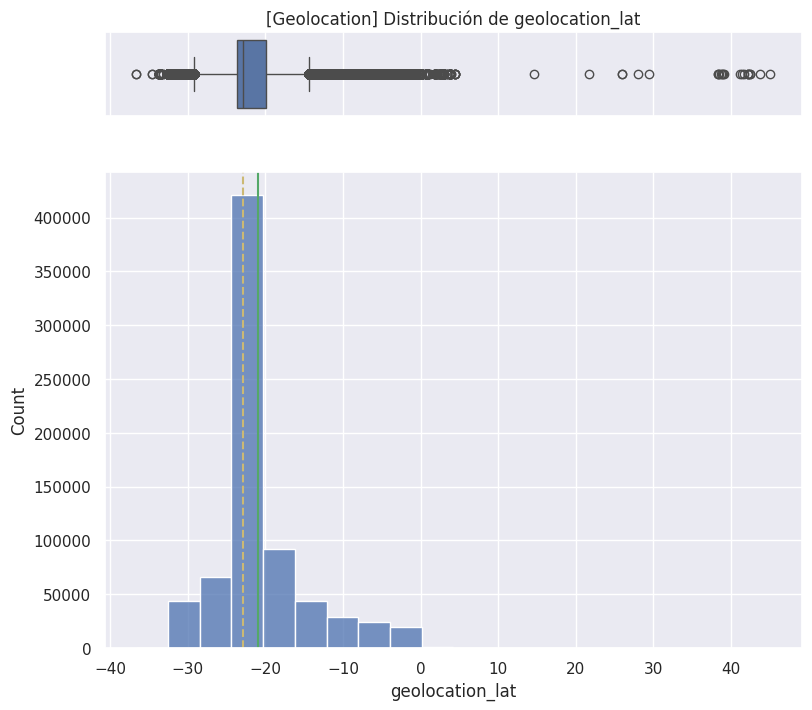

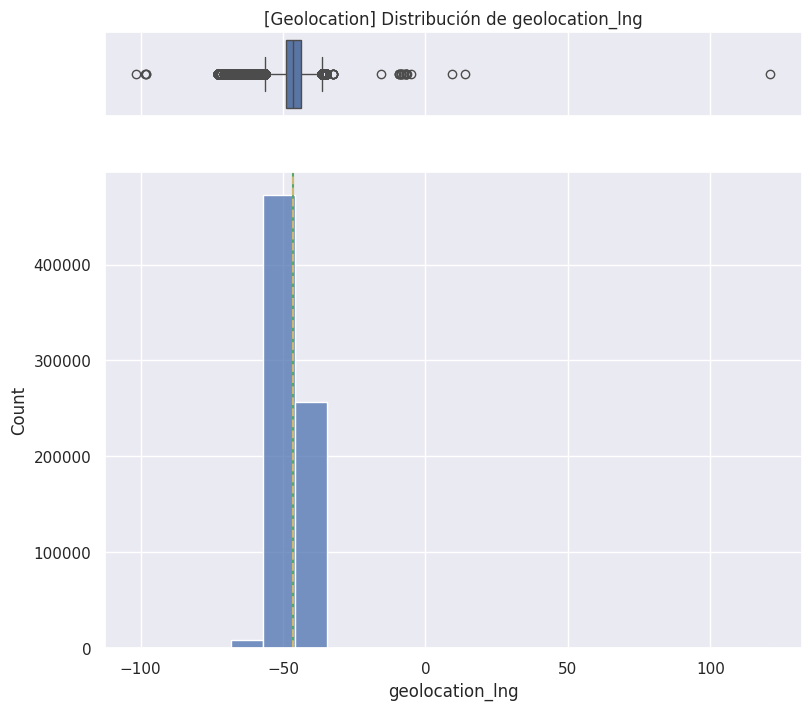

CATEGORY TRANSLATION


In [ ]:
for nombre, df in datasets.items():
    cols = [c for c in df.select_dtypes(include=[np.number]).columns
    if '_id' not in col.lower()
    ]
    print("=" * 80)
    print(nombre.upper())
    print("=" * 80)
    for col in cols:
        histogram_boxplot(
            df[col].dropna(),
            bins=20,
            font_scale=1,
            title=f"[{nombre}] Distribución de {col}"
        )

#####Primero realizamos la detección de outliers de variables numéricas

- CUSTOMERS
  - No hay outliers
- ORDERS
  - No hay outliers
- ORDER_ITEMS
  - Price puede haber outliers, la mayoría de precios no supera 1.000, luego hay unos cuantos de 3.000 a 5.000 y apenas un par cerca de 7.000. Pueden ser articulos muy caros
  - Freight_value contiene una distribución similar, pueden ser outliers aunque esto mantiene la tesis de productos caros o de gran tamaño
- PAYMENTS
  - payment_value contiene una distribución similar, pueden ser outliers aunque esto mantiene la tesis de productos caros o de gran tamaño
  - payment_installments tiene un outlier aparentemente
- PRODUCTS
  - product_weight_g contiene una distribución similar, pueden ser outliers aunque esto mantiene la tesis de productos caros o de gran tamaño
  - product dimensions (lenght, width y height_cm aparentemente cuentan todos con posibles outliers)

In [ ]:
#Antes del análisis gráfico, debemos convertir en category aquellas variables que nos interesa (las que tienen menos de 10 valores unicos)
for nombre, df in datasets.items():
    to_category = df.columns[df.nunique() <= 10]

    df[to_category] = df[to_category].astype('category')

In [ ]:
## Función para gráfico de barras de variables categóricas
def cat_plot(col):
     if col.dtype in ['object', 'category']:
        fig = px.bar(col.value_counts())
        #fig = sns.countplot(x=col)
        return(fig)

In [ ]:
#Ahora hacemos el mismo análisis gráfico para las variables categoricas.

for nombre, df in datasets.items():
    cols = [
        col for col in df.select_dtypes(include=['object', 'category']).columns
        if '_id' not in col.lower()
        and col not in ['review_comment_title','review_comment_message']

    ]
    if not cols:
        print(f"[{nombre}] No hay columnas numéricas para analizar.\n")
        continue
    print("=" * 80)
    print(nombre.upper())
    print("=" * 80)

    for col in cols:
        cat_plot(df[col]).show()

CUSTOMERS


ORDERS


[Order Items] No hay columnas numéricas para analizar.

PAYMENTS


REVIEWS


PRODUCTS


SELLERS


GEOLOCATION


CATEGORY TRANSLATION


#####A continuación procedemos a la detección de outliers de variables categóricas

En el caso de las variables categóricas, no hay ningún outlier reseñable.

##### Análisis de simetría de las columnas del DF
Primero comprobamos si se trata de una distribucion simétrica o no, y aplicamos los criterios explicados en clase
  1. si es simétrica, seguimos criterio de Media-SD y después de IQR
  2. Si no es simétrica, seguimos criterio de MAD y después de IQR
De la combinación de ambos criterios se extrae la siguiente tabla, cuya interpretación es: valores por encima de 1 suponen la existencia importante de outliers -> hay que gestionarlos en esas variables.

Asimetrías en valor absoluto mayores a la unidad son signo de distribución significativamente sesgada a la derecha/positiva (+) o izquierda/negativa (-).

En nuestro caso, hay asimetrías relevantes (exceptuando ID y otras similares) sesgadas a la derecha en price, freigth_value, payment_value, payment_sequential y (mas pequeña) en los product dimensions de PRODUCTS

In [ ]:
#dataset.select_dtypes(include=np.number).apply(lambda x: x.skew())
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.select_dtypes(include=np.number).apply(lambda x: x.skew()))


Customers


,0



Orders


,0



Order Items


...

,0



Geolocation


,0
geolocation_lat,1.477274
geolocation_lng,-0.044910



Category Translation


,0


#####Gestión de outliers
Hay tenemos dos formas de gestionar los outliers:
1. Utilizando la función gestiona_outliers, que bien los winsoriza (colapsa las colas) o bien los transforma a missing. En esta alternativa, dados los valores outliers en nuestros datos, lo más inteligente sería winsorize, es decir, recortar al percentil 1-99, o a Q1-1.5·IQR / Q3+1.5·IQR debido a que:
    - Entendemos que el valor es real y válido, solo extremo, como en el caso de price
    - Queremos conservar el tamaño muestral para modelar (regresión, clustering), y perder filas reduce la potencia estadística o sesga el dataset.
    - La variable va a alimentar un modelo sensible a la escala/varianza (regresión lineal, k-means, PCA) y el outlier distorsiona coeficientes o distancias, pero sigue siendo información de "algo pasó, fue un valor alto/bajo", no ruido.
    - Son variables continuas con colas largas por naturaleza: price, freight_value, payment_value, product_weight_g, delivery_days.
2. Mediante un análisis de negocio, comprobando usando el pensamiento crítico si se trata de outliers o son simplemente casos particulares de compras, por ejemplo de artículos muy caros o de gran tamaño, o con pagos con condiciones especiales.

Vamos a comenzar a gestionarlos con esta segunda alternativa. Si no conseguimos que tenga sentido, winsorizaremos los outliers.

In [ ]:
## Función para gestionar outliers
def gestiona_outliers(col,clas = 'check'):

     print(col.name)
     # Condición de asimetría y aplicación de criterio 1 según el caso
     if abs(col.skew()) < 1:
        criterio1 = abs((col-col.mean())/col.std())>3
     else:
        criterio1 = abs((col-col.median())/stats.median_abs_deviation(col.dropna()))>6 ## Considerar solo valores válidos!! dropna().

     # Calcular primer cuartil
     q1 = col.quantile(0.25)
     # Calcular tercer cuartil
     q3 = col.quantile(0.75)
     # Calculo de IQR
     IQR=q3-q1
     # Calcular criterio 2 (general para cualquier asimetría)
     criterio2 = (col<(q1 - 3*IQR))|(col>(q3 + 3*IQR))
     lower = col[criterio1&criterio2&(col<q1)].count()/col.dropna().count()
     upper = col[criterio1&criterio2&(col>q3)].count()/col.dropna().count()
     # Salida según el tipo deseado
     if clas == 'check':
            return(lower*100,upper*100,(lower+upper)*100)
     elif clas == 'winsor':
            return(winsorize_with_pandas(col,(lower,upper)))
     elif clas == 'miss':
            print('\n MissingAntes: ' + str(col.isna().sum()))
            col.loc[criterio1&criterio2] = np.nan
            print('MissingDespues: ' + str(col.isna().sum()) +'\n')
            return(col)

#####La forma de aplicar winsor sería la siguiente, que dejamos on hold en caso de ser necesaria

datasets_winsor = {
    nombre: df.copy()
    for nombre, df in datasets.items()
}

for name, df in datasets_winsor.items():
    cols = [col for col in df.select_dtypes(include=np.number).columns
    if '_id' not in col.lower()
    ]
    df[cols] = df[cols].apply(
        lambda x: gestiona_outliers(x, clas='winsor')
    )
    print(f"\n{nombre}")
    print(missing)

Esto se puede comprobar de forma gráfica con:

for nombre, df in datasets_winsor.items():
    cols = [c for c in df.select_dtypes(include=[np.number]).columns]
    print("=" * 80)
    print(nombre.upper())
    print("=" * 80)
    for col in cols:
        histogram_boxplot(
            df[col].dropna(),
            bins=20,
            font_scale=1,
            title=f"[{nombre}] Distribución de {col}"
        )

###### Gestión de outliers con análisis de negocio

Vamos a analizar de esta forma:
- ORDER_ITEMS: price y freigth_value

- PAYMENTS: payment_value y payment_installment

- PRODUCTS: product_weight y las columnas de dimensiones

In [ ]:
#1. price de ORDER_ITEMS
Q1 = order_items["price"].quantile(0.25)
Q3 = order_items["price"].quantile(0.75)
IQR=Q3-Q1

price_outliers = order_items[
    order_items["price"] > (Q3 + 1.5 * IQR)
]

# Unimos los precios outliers con la tabla de PRODUCTS
price_products = price_outliers.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Unimos los precios outliers con la tabla de CAT_TRANSLATIONS
price_products = price_products.merge(
    cat_translation,
    on="product_category_name",
    how="left"
)

# Creamos una tabla resumen de estos outliers organizados por las categorías
price_summary = (
    price_products
    .groupby("product_category_name_english")["price"]
    .agg(
        Count="count",
        Minimum_Price="min",
        Median_Price="median",
        Maximum_Price="max"
    )
    .sort_values(by="Count", ascending=False)
)

price_summary

,Count,Minimum_Price,Median_Price,Maximum_Price
product_category_name_english,,,,
health_beauty,1157,277.72,370.00,3124.00
watches_gifts,975,277.85,559.90,3999.90
sports_leisure,485,278.00,389.00,4059.00
auto,425,278.00,429.90,2258.00
cool_stuff,390,278.99,539.99,3109.99
...,...,...,...,...
arts_and_craftmanship,1,289.49,289.49,289.49
fashion_male_clothing,1,292.50,292.50,292.50
books_imported,1,749.00,749.00,749.00


Conclusiones de los outliers en Price

El análisis de outliers en las distintas categorías de productos indica que la mayoría de los productos de alto precio se concentran en categorías donde se espera un precio premium, como health_beauty, watches_gifts, sports_leisure, Auto, y cool_stuff.

Estas categorías suelen tener productos de lujo, de marca o de alto valor, lo que explica la presencia de precios más elevados. Los precios máximos observados son razonables para este tipo de productos y no sugieren valores irreales o erróneos.

Varias categorías contienen solo uno o pocos productos atípicos. Si bien estas observaciones son menos frecuentes, sus precios siguen siendo razonables para sus respectivas categorías y no indican problemas evidentes de calidad de los datos.

En general, los precios atípicos detectados representan una variabilidad real del mercado, en lugar de registros incorrectos o anómalos.

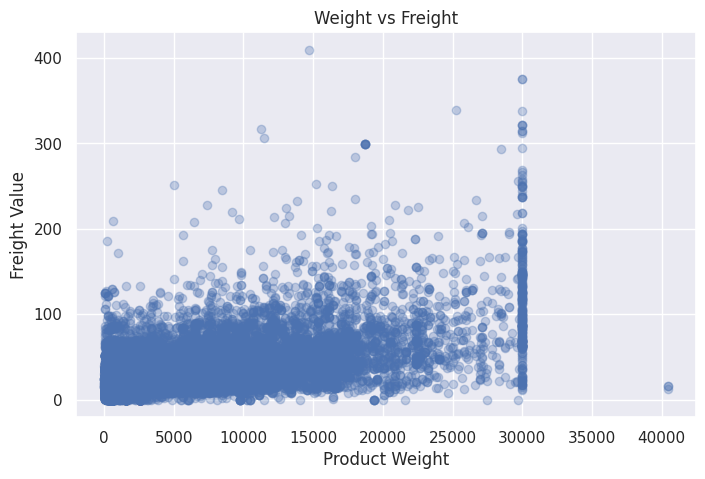

In [ ]:
#2. freight_value de ORDER_ITEMS
freight = order_items.merge(
    products[["product_id","product_weight_g"]],
    on="product_id"
)

freight[["freight_value","product_weight_g"]].corr()

plt.figure(figsize=(8,5))

plt.scatter(
    freight["product_weight_g"],
    freight["freight_value"],
    alpha=0.3
)

plt.xlabel("Product Weight")
plt.ylabel("Freight Value")
plt.title("Weight vs Freight")

plt.show()

In [ ]:
correlation = freight["product_weight_g"].corr(freight["freight_value"])

print(f"Correlation: {correlation:.3f}")

Correlation: 0.610


Conclusiones de outliers en Freight_value

El análisis muestra una correlación positiva moderadamente fuerte entre el peso del producto y el coste del flete (r = 0,609), lo que indica una que a mayor peso, mayor es el coste de envío. Esto es una correlación lógica en el mundo del transporte, y aunque puede haber otros factores como las condiciones de la empresa de transporte, los outliers observados siguen patrones comerciales esperados y, por lo tanto, se consideran consistentes en lugar de problemas de calidad de los datos.

In [ ]:
#3. payment_value de PAYMENTS
order_summary = order_items.groupby("order_id").agg(
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum")
)

payment_summary = order_payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum")
)

comparison = (
    order_summary
    .join(payment_summary)
)

comparison["expected_total"] = (
    comparison["total_price"] +
    comparison["total_freight"]
)

comparison["difference"] = (
    comparison["total_payment"] -
    comparison["expected_total"]
)

comparison.sort_values(
    "difference",
    ascending=False
).head(20)

,total_price,total_freight,total_payment,expected_total,difference
order_id,,,,,
ce6d150fb29ada17d2082f4847107665,1299.00,104.66,1586.47,1403.66,182.81
6e5fe7366a2e1bfbf3257dba0af1267f,179.19,108.72,406.92,287.91,119.01
70b742795bc441e94a44a084b6d9ce7a,269.99,196.94,578.82,466.93,111.89
996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,664.43,587.90,76.53
70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,274.84,213.15,61.69
bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,303.02,242.01,61.01
af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,466.97,413.17,53.80
bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,394.36,348.93,45.43
8d9c0dc8d5a2ce804f6b925d8f8e6c1d,209.80,44.65,293.89,254.45,39.44


Conclusiones de outliers en payment_value

Tras comparar el importe total del pago con el valor esperado del pedido (precio del producto + coste del envío), las diferencias entre ambos disminuyeron considerablemente. Esto indica que la mayoría de las discrepancias detectadas inicialmente se debían a los gastos de envío y no a anomalías.

Las diferencias restantes son relativamente pequeñas en comparación con el valor total del pedido y probablemente se deban a factores como el proceso del pago, los pagos a plazos o pequeños ajustes financieros. No se observó ninguna evidencia de importes de pago irreales o erróneos.

En general, las discrepancias en los importes de pago se consideran coherentes con las transacciones comerciales habituales.

In [ ]:
#4. payment_installments de PAYMENTS
order_payments["payment_installments"].value_counts().sort_index()

,count
payment_installments,
0,2
1,52546
2,12413
3,10461
4,7098
5,5239
6,3920
7,1626
8,4268


In [ ]:
order_payments.groupby(
    "payment_installments"
)["payment_value"].mean()

,payment_value
payment_installments,
0,94.315000
1,112.420229
2,127.228150
3,142.539317
4,163.976840
5,183.465222
6,209.849952
7,187.673672
8,307.737427


Conclusiones de outliers en payment_installments

Tras comparar el importe del pago con el número de cuotas, se observa que los valores generalmente aumentan a medida que se incrementa el número de cuotas. Esto indica que los clientes tienden a utilizar planes de pago a plazos para compras de mayor valor.

Se observaron algunas fluctuaciones en ciertas categorías de cuotas, pero probablemente se deban a diferencias en el volumen de transacciones o a la presencia de pedidos de alto valor. No se identificaron patrones inusuales ni inconsistencias importantes.

En general, la relación entre las cuotas y el importe del pago se considera coherente con el comportamiento de pago habitual de los clientes.

In [ ]:
# 5. product_weight de PRODUCTS
Q1 = products["product_weight_g"].quantile(0.25)
Q3 = products["product_weight_g"].quantile(0.75)
IQR = Q3 - Q1

heavy_products = products[
    products["product_weight_g"] > (Q3 + 1.5 * IQR)
]

# Unimos con las traducciones
heavy_products = heavy_products.merge(
    cat_translation,
    on="product_category_name",
    how="left"
)

# Resumen por categoría
heavy_summary = (
    heavy_products
    .groupby("product_category_name_english")["product_weight_g"]
    .agg(
        Count="count",
        Median_Weight="median",
        Maximum_Weight="max"
    )
    .sort_values(by="Count", ascending=False)
)

heavy_summary


,Count,Median_Weight,Maximum_Weight
product_category_name_english,,,
furniture_decor,483,8450.0,30000.0
housewares,470,9275.0,30000.0
bed_bath_table,378,7812.5,40425.0
auto,372,6900.0,30000.0
sports_leisure,302,7500.0,30000.0
office_furniture,287,12160.0,30000.0
baby,238,9733.5,30000.0
toys,162,7237.5,30000.0
pet_shop,160,8475.0,30000.0


Conclusiones de outliers en los weight

Tras analizar las categorías que contienen productos pesados, se observa que la mayor concentración de artículos pesados ​​se encuentra en categorías como muebles y decoración, artículos para el hogar, cama, baño y mesa, y automoción. Estas categorías, naturalmente, contienen productos más grandes y voluminosos, lo que explica su mayor peso.

Algunas categorías, como muebles, colchones y tapicería, y mobiliario de oficina, presentan pesos medianos elevados, lo que indica que sus productos son consistentemente más pesados, en lugar de verse afectados únicamente por valores extremos.

En general, la distribución del peso de los productos se considera coherente con las características típicas de los productos de comercio electrónico, donde las categorías de muebles, hogar y artículos voluminosos aportan la mayor parte de los productos pesados.

In [ ]:
#6. Dimensiones de productos de PRODUCTS
products["volume"] = (
    products["product_length_cm"] *
    products["product_width_cm"] *
    products["product_height_cm"]
)

products[[
    "volume",
    "product_weight_g"
]].corr()

,volume,product_weight_g
volume,1.000000,0.803005
product_weight_g,0.803005,1.000000


Conclusiones de outliers en dimensiones de productos

Tras analizar la correlación entre el volumen y el peso del producto, se observó una fuerte relación positiva con un coeficiente de correlación de 0,80.

Esto indica que los productos de mayores dimensiones tienden a pesar más, lo cual es previsible en productos físicos donde el tamaño y el peso suelen estar relacionados. Sin embargo, la correlación no es perfecta, lo que significa que algunos productos pueden tener un volumen elevado pero un peso relativamente bajo debido a diferencias en la densidad del material.

En general, la relación entre el volumen y el peso del producto se considera coherente con las características normales del producto.

####6.  Gestionamos los missing de los DF ya vistos anteriormente.

Sabemos del análisis previo que se encuentran en ORDERS, REVIEWS y PRODUCTS. No se han creado nuevos missing.

Tenemos varias alternativas de imputación de missing, como imputación simple (media y mediana para continuas, moda para categóricas y aleatoria) y multivariante (KNN y Markov para continuas). También podemos imputar usando la lógica.

order_approved_at	160
order_delivered_carrier_date	1783
order_delivered_customer_date 2965



In [ ]:
#5. Gestionamos los missing de los DF ya vistos anteriormente. Para recordarlos, repetimos la tabla de la celda 15:
overview = pd.DataFrame({
    "Dataset": datasets.keys(),
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()],
    "Missing Values": [df.isnull().sum().sum() for df in datasets.values()],
})
overview

,Dataset,Rows,Columns,Missing Values
0,Customers,99441,5,0
1,Orders,99441,8,4908
2,Order Items,112650,7,0
3,Payments,103886,5,0
4,Reviews,99224,5,0
5,Products,32951,10,2450
6,Sellers,3095,4,0
7,Geolocation,738332,5,0
8,Category Translation,71,2,0


In [ ]:
#Definimos los imputadores para tenerlos preparados para transformar datos o predecir o lo que sea necesario

# Moda: Solo nominales
imputer_moda = skl_imp.SimpleImputer(strategy='most_frequent', missing_values=np.nan)

# knn: Solo numéricas
imputer_knn = skl_imp.KNNImputer(n_neighbors=3)

# Chain equations: solo numéricas
imputer_itImp = skl_imp.IterativeImputer(max_iter=10, random_state=0)

# Aleatoria: numéricas y nominales
imputer_rand = fe_imp.RandomSampleImputer()

# Mediana: solo numéricas
imputer_median = fe_imp.MeanMedianImputer(imputation_method='median')

# Media: solo numericas
imputer_mean = fe_imp.MeanMedianImputer(imputation_method='mean')

###### Missing en ORDERS

Antes de imputar estos missing, tenemos que razonar qué pueden ser. Al ser todos de tipo temporal, puede deberse a que, a la fecha de extracción del dataset, esa parte del proceso no se hubiera completado. Por tanto, lo primero que hacemos es ver el status de los datos perdidos (canceled, delivered, created, approved, invoiced, processing, shipped, unavailable)

Aquellos missing que aparecen como delivered sí que pueden ser modificados, ya que es un valor faltante que tiene sentido rellenar.

Los que no habría que mantenerlos como missing debido a que estos casos representan escenarios comerciales válidos, en lugar de datos faltantes.

In [ ]:
# ¿Los missing de cada columna coinciden con pedidos que no llegaron a esa etapa?
print(orders.loc[orders['order_approved_at'].isna(), 'order_status'].value_counts())
print(orders.loc[orders['order_delivered_carrier_date'].isna(), 'order_status'].value_counts())
print(orders.loc[orders['order_delivered_customer_date'].isna(), 'order_status'].value_counts())

order_status
canceled       141
delivered       14
created          5
approved         0
invoiced         0
processing       0
shipped          0
unavailable      0
Name: count, dtype: int64
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
shipped          0
Name: count, dtype: int64
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [ ]:
#1. order_approved_at. Calculamos la mediana del retraso en aprobar la orden
approval_delay = (
    orders["order_approved_at"] -
    orders["order_purchase_timestamp"]
).dropna().median()

# Completamos solo las órdenes que por lógica deberían estar aprobadas
mask = (
    orders["order_approved_at"].isna()
    &
    orders["order_status"].isin([
        "approved",
        "processing",
        "invoiced",
        "shipped",
        "delivered"
    ])
)

orders.loc[mask, "order_approved_at"] = (
    orders.loc[mask, "order_purchase_timestamp"] +
    approval_delay
)

In [ ]:
#2. order_delivered_carrier_date

# Igual que antes, calculamos la mediana del retraso en envío
carrier_delay = (
    orders["order_delivered_carrier_date"] -
    orders["order_approved_at"]
).dropna().median()

# Completamos solo las órdenes entregadas
mask = (
    orders["order_delivered_carrier_date"].isna()
    &
    (orders["order_status"] == "delivered")
)

orders.loc[mask, "order_delivered_carrier_date"] = (
    orders.loc[mask, "order_approved_at"] +
    carrier_delay
)

In [ ]:
#3. order_delivered_customer_date

# Calculamos la mediana de retraso en entrega
delivery_delay = (
    orders["order_delivered_customer_date"] -
    orders["order_delivered_carrier_date"]
).dropna().median()

# Completamos solo las órdenes entregadas
mask = (
    orders["order_delivered_customer_date"].isna()
    &
    (orders["order_status"] == "delivered")
)

orders.loc[mask, "order_delivered_customer_date"] = (
    orders.loc[mask, "order_delivered_carrier_date"] +
    delivery_delay
)

In [ ]:
# Verificación posterior
print("\nMissing después:")
print(orders[['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']].isna().sum())


Missing después:
order_approved_at                 146
order_delivered_carrier_date     1781
order_delivered_customer_date    2957
dtype: int64


###### Missing en PRODUCTS

Los valores perdidos en este dataset son probablemente debidos a que el vendedor no completó los datos en product_category_name, product_name_lenght, product_description_lenght y product_photos_qty	(610 missing en todos ellos, probablemente los mismos). Además, hay solo 2 missing (seguramente también los mismos) en product_weight_g, product_length_cm, product_height_cm, y product_width_cm.

Dado que son muy pocos, para los que faltan 2 valores vamos a imputar usando la lógica:

- product_category_name será "Unknown category" dado que no se le ha dado una
- product_name_lenght, product_description_lenght serán "Unknown", porque puede ser que el vendedor no quiso crear una descripción o un nombre para el producto y usar mediana o media supondría nombrar artículos de forma errónea (por ejemplo, nombrar a una sombrilla como cámara, no tiene sentido)
- product_photos_qty será "0" dado que resulta razonable asumir que no hay valores al no haber fotos
- Las categorías de pesos serán imputadas por la mediana, son muy pocos valores y no hay que sobrepensar esto al no ser relevante

In [ ]:
# Verificación previa
print(products.isna().sum())

# 1. Categoría desconocida de producto
products['product_category_name'] = products['product_category_name'].fillna('Unknown category')

# 2. Longitud de nombre y descripción desconocidas
products['product_name_lenght'] = products['product_name_lenght'].fillna('0')
products['product_description_lenght'] = products['product_description_lenght'].fillna('0')

# 3. Ausencia de fotos
products['product_photos_qty'] = products['product_photos_qty'].fillna(0)

# 4. Peso y dimensiones usando la mediana
cols_dimensiones = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'volume']
for col in cols_dimensiones:
    products[col] = products[col].fillna(
        products.groupby('product_category_name')[col].transform('median')
    )
# Verificación final
print("\nMissing después de imputar:")
print(products.isna().sum())

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
volume                          2
dtype: int64

Missing después de imputar:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
volume                        0
dtype: int64


##3. Construcción del dataset analítico (Extracción de datasets limpios)

###3.2 Integración de tablas y granularidad de análisis

In [ ]:
orders.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/orders_clean.csv", index=False)
customers.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/customers_clean.csv", index=False)
order_items.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_items_clean.csv", index=False)
order_payments.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_payments_clean.csv", index=False)
products.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/products_clean.csv", index=False)
order_reviews.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_reviews_clean.csv", index=False)
sellers.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/sellers_clean.csv", index=False)
geolocation.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/geolocation_clean.csv", index=False)
cat_translation.to_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/cat_translation_clean.csv", index=False)

In [ ]:
orders_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/orders_clean.csv")
customers_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/customers_clean.csv")
order_items_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_items_clean.csv")
order_payments_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_payments_clean.csv")
products_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/products_clean.csv")
order_reviews_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/order_reviews_clean.csv")
sellers_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/sellers_clean.csv")
geolocation_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/geolocation_clean.csv")
cat_translation_clean = pd.read_csv("/content/drive/MyDrive/TFM Trabajo/clean_datasets/cat_translation_clean.csv")

###Pasos previos a la integración

Es necesario modificar algunos de los dataset antes de unificarlos. Dado que se establecen los id de orders como el nexo, no pueden estar duplicados. Para evitarlo, hacemos:

1. Aquellas orders con más de una review se eliminan. Solo nos quedamos con la respuesta más reciente para evitar tener más order_id de las debidas. Elegimos esta opción dado que probablemente sea la review más cierta, otras pueden deberse al proceso más que al producto.
2. Agregamos el dataset de geolocation por prefijo, usando las coordenadas medias en aquellos casos con más de un set de coordenadas, para poder así no multiplicar las filas al unificarlo. De esta forma, se transforma la tabla geolocation de una estructura con múltiples registros por código postal a una estructura con un único registro por geolocation_zip_code_prefix, para poder después unirla con customers y sellers.
3. Unificamos los estados en 5 regiones (en customers y en sellers) para así poder tener una categórica de pocos valores únicos con los que obtener más información, adecuada para el tipo de geografía política de Brasil.
4. Traducción de categoría, manteniendo el nombre original en portugués de las dos categorías sin traducción, para evitar perder información de categoría real sin necesidad.

Finalizados esos pasos, pasamos a integrar de dos formas: a nivel de ítem, para los apartados 4.3, 9.2 y 8.1 del trabajo y a nivel de pedido, para los apartados restantes.

In [ ]:
# Paso 1. Eliminar reviews (regla: nos quedamos con la respuesta más reciente)
print("Reviews antes:", order_reviews.shape[0])
print("order_id duplicados:", order_reviews['order_id'].duplicated().sum())

order_reviews_dup = (
    order_reviews
    .sort_values('review_answer_timestamp')
    .drop_duplicates(subset='order_id', keep='last')
)

print("Reviews después:", order_reviews_dup.shape[0])
assert order_reviews_dup['order_id'].is_unique

Reviews antes: 99224
order_id duplicados: 551
Reviews después: 98673


In [ ]:
# Paso 2. geolocation es N:1 respecto a zip_code_prefix -> agregamos por prefijo
geo_agg = (
    geolocation
    .groupby('geolocation_zip_code_prefix')
    .agg(
        lat_mean=('geolocation_lat', 'mean'),
        lng_mean=('geolocation_lng', 'mean'),
        city_mean=('geolocation_city', lambda x: x.mode().iat[0]),
        state_mean=('geolocation_state', lambda x: x.mode().iat[0]),
    )
    .reset_index()
)
print(geo_agg.shape)

geo_agg['geolocation_zip_code_prefix'].astype('string').str.zfill(5)

(19015, 5)


,geolocation_zip_code_prefix
0,01001
1,01002
2,01003
3,01004
4,01005
...,...
19010,99960
19011,99965
19012,99970
19013,99980


In [ ]:
# Paso 3. Siguiendo el diccionario oficial del estado, organizamos los 27 estados por regiones (IBGE)
state_to_region = {
    # Norte
    'AM': 'Norte', 'PA': 'Norte', 'AC': 'Norte', 'RR': 'Norte',
    'AP': 'Norte', 'RO': 'Norte', 'TO': 'Norte',
    # Nordeste
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste',
    'PB': 'Nordeste', 'PE': 'Nordeste', 'AL': 'Nordeste', 'SE': 'Nordeste', 'BA': 'Nordeste',
    # Centro-Oeste
    'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste',
    # Sudeste
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'MG': 'Sudeste', 'ES': 'Sudeste',
    # Sur
    'PR': 'Sur', 'SC': 'Sur', 'RS': 'Sur',
}

customers['customer_region'] = customers['customer_state'].map(state_to_region)
sellers['seller_region'] = sellers['seller_state'].map(state_to_region)

# Comprobación: si algo no mapea, hay un código de estado inesperado (typo, NaN, etc.)
assert customers['customer_region'].isna().sum() == 0, "Hay customer_state sin mapear"
assert sellers['seller_region'].isna().sum() == 0, "Hay seller_state sin mapear"

customers['customer_region'].value_counts()

,count
customer_region,
Sudeste,68266
Sur,14148
Nordeste,9394
Centro-Oeste,5782
Norte,1851


In [ ]:
# Paso 4. Traducción de categoría
products_cat = products_clean.merge(cat_translation_clean, on='product_category_name', how='left')

products_cat['product_category_name_english'] = (
    products_cat['product_category_name_english']
    .fillna(products_cat['product_category_name'])
)

In [ ]:
#Integración por order_items: une item + producto + vendedor + geolocalización
order_items_integrada = (
    order_items
    .merge(orders, on='order_id', how='left')
    .merge(products_cat[['product_id', 'product_category_name_english',
                          'product_weight_g', 'volume']], on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left')
    .merge(geo_agg.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                   'geo_lat': 'seller_lat', 'geo_lng': 'seller_lng'}),
           on='seller_zip_code_prefix', how='left')
)
print("order_items_detail:", order_items_integrada.shape)

order_items_detail: (112650, 25)


In [ ]:
order_items_integrada

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_weight_g,volume,seller_zip_code_prefix,seller_city,seller_state,seller_region,lat_mean,lng_mean,city_mean,state_mean
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,650.0,3528.0,27277,volta redonda,SP,Sudeste,-22.497188,-44.127324,volta redonda,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,30000.0,60000.0,03471,sao paulo,SP,Sudeste,-23.565754,-46.519097,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,3050.0,14157.0,37564,borda da mata,MG,Sudeste,-22.262802,-46.170735,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,200.0,2400.0,14403,franca,SP,Sudeste,-20.553651,-47.387145,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,3750.0,42000.0,87900,loanda,PR,Sur,-22.929583,-53.135750,loanda,PR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,...,10150.0,53400.0,88303,itajai,SC,Sur,-26.912506,-48.674090,itajai,SC
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,...,8950.0,44460.0,01206,sao paulo,SP,Sudeste,-23.535839,-46.642848,sao paulo,SP
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,...,967.0,9576.0,80610,curitiba,PR,Sur,-25.469563,-49.288176,curitiba,PR
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,...,100.0,8000.0,04733,sao paulo,SP,Sudeste,-23.637701,-46.695548,sao paulo,SP


In [ ]:
# Integración desde order_items (a nivel pedido)
items_agg = order_items_integrada.groupby('order_id').agg(
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    n_items=('order_item_id', 'count'),
    n_sellers_distintos=('seller_id', 'nunique'),
    categoria_principal=('product_category_name_english',
                          lambda x: x.mode().iat[0] if not x.mode().empty else np.nan),
    peso_total_g=('product_weight_g', 'sum'),
).reset_index()

# Agregados desde order_payments (un pedido puede tener varios pagos)
payments_agg = order_payments.groupby('order_id').agg(
    total_payment=('payment_value', 'sum'),
    n_pagos=('payment_sequential', 'count'),
    max_installments=('payment_installments', 'max'),
    payment_type_principal=('payment_type', lambda x: x.mode().iat[0]),
).reset_index()

# Tabla ancla + todo lo demás, empezando SIEMPRE desde orders
orders_analytical = (
    orders
    .merge(customers, on='customer_id', how='left')
    .merge(items_agg, on='order_id', how='left')
    .merge(payments_agg, on='order_id', how='left')
    .merge(order_reviews_dup[['order_id', 'review_score',
                                 'review_creation_date', 'review_answer_timestamp']],
           on='order_id', how='left')
    .merge(geo_agg.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                    'geo_lat': 'customer_lat', 'geo_lng': 'customer_lng'}),
           on='customer_zip_code_prefix', how='left')
)
print("orders_analytical:", orders_analytical.shape)
assert orders_analytical.shape[0] == orders.shape[0]  # nunca debe crecer respecto a orders

orders_analytical: (99441, 30)


In [ ]:
# Paso 6. Trazabilidad de la union, para comprobar que se mantiene el nº de pedidos inicial
trazabilidad = pd.DataFrame({
    "Paso": ["Pedidos iniciales", "Tras dedup reviews",
             "Tras merge items+payments+reviews", "Dataset final analítico"],
    "Filas": [orders.shape[0], orders.shape[0],
              orders_analytical.shape[0], orders_analytical.shape[0]]
})
trazabilidad

,Paso,Filas
0,Pedidos iniciales,99441
1,Tras dedup reviews,99441
2,Tras merge items+payments+reviews,99441
3,Dataset final analítico,99441


In [ ]:
order_items_integrada.to_csv("order_items_detail.csv", index=False)
orders_analytical.to_csv("orders_analytical.csv", index=False)
pd.set_option('display.max_columns', None)
display(orders_analytical)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_region,total_price,total_freight,n_items,n_sellers_distintos,categoria_principal,peso_total_g,total_payment,n_pagos,max_installments,payment_type_principal,review_score,review_creation_date,review_answer_timestamp,lat_mean,lng_mean,city_mean,state_mean
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,Sudeste,29.99,8.72,1.0,1.0,housewares,500.0,38.71,3.0,1.0,voucher,4,2017-10-11,2017-10-12 03:43:48,-23.577482,-46.587077,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,Nordeste,118.70,22.76,1.0,1.0,perfumery,400.0,141.46,1.0,1.0,boleto,4,2018-08-08,2018-08-08 18:37:50,-12.186877,-44.540232,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,Centro-Oeste,159.90,19.22,1.0,1.0,auto,420.0,179.12,1.0,3.0,credit_card,5,2018-08-18,2018-08-22 19:07:58,-16.745150,-48.514783,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,Nordeste,45.00,27.20,1.0,1.0,pet_shop,450.0,72.20,1.0,1.0,credit_card,5,2017-12-03,2017-12-05 19:21:58,-5.774002,-35.270976,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,09195,santo andre,SP,Sudeste,19.90,8.72,1.0,1.0,stationery,250.0,28.62,1.0,1.0,credit_card,5,2018-02-17,2018-02-18 13:02:51,-23.676257,-46.514580,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP,Sudeste,72.00,13.08,1.0,1.0,health_beauty,1175.0,85.08,1.0,3.0,credit_card,5,2017-03-22,2017-03-23 11:02:08,-23.177943,-45.882139,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP,Sudeste,174.90,20.10,1.0,1.0,baby,4950.0,195.00,1.0,3.0,credit_card,4,2018-03-01,2018-03-02 17:50:01,-24.001334,-46.450022,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA,Nordeste,205.99,65.02,1.0,1.0,home_appliances_2,13300.0,271.01,1.0,5.0,credit_card,5,2017-09-22,2017-09-22 23:10:57,-17.898045,-39.373106,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ,Sudeste,359.98,81.18,2.0,1.0,computers_accessories,13100.0,441.16,1.0,4.0,credit_card,2,2018-01-26,2018-01-27 09:16:56,-22.563909,-42.695343,japuiba,RJ


##3. Construcción del dataset analítico

###3.3. Definición de variables objetivo (modelos supervisados)
###3.4. Variables derivadas principales

En este bloque se definen, sobre el dataset integrado, las variables objetivo para los problemas de negocio 1 y 2 y variables derivadas del dataset

###3.3. Definición de variables objetivo (modelos supervisados)

1. **Insatisfacción del cliente (problema 1).** Se define como todas aquellas review <= 3. Las que no tienen valoración se asumen como buenas, para poder mantener la distribución binaria, ya que son una minoría y generalmente resulta asumible que la ausencia de valoración se debe a que la compra ha sido aceptable.

2. **Riesgo de retraso en la entrega (problema 2).** Sobre pedidos entregados, porque son los únicos que tienen fecha real de entrega. El resto de estados se deja como NaN en lugar de imputarse o excluirse de la tabla, para no perder esos pedidos en análisis que no dependan de esta variable en concreto.

Los problemas 3, 4 y 5 no se definen mediante un target binario
directamente sobre el pedido, sino en los capítulos 7-9 a partir de agregaciones:
- Problema 3: riesgo y desempeño del vendedor.
- Problema 4: segmentación y comportamiento del cliente.
- Problema 5: priorización geográfica y análisis territorial.
Estas agregaciones se realizarán en los capítulos correspondientes, utilizando la granularidad adecuada para cada problema.

In [ ]:
# 1. Insatisfacción del cliente
orders_analytical['review_score'] = pd.Categorical(orders_analytical['review_score'], categories=[1, 2, 3, 4, 5], ordered=True)
orders_analytical['insatisfaccion'] = (
    orders_analytical['review_score'].le(3).astype(int)
)

print("Porcentaje de Insatisfaccion (1) en las compras online en Brasil:")
print(orders_analytical['insatisfaccion'].value_counts(dropna=False, normalize=True).round(3))

Porcentaje de Insatisfaccion (1) en las compras online en Brasil:
insatisfaccion
0    0.772
1    0.228
Name: proportion, dtype: float64


In [ ]:
# 2. Riesgo de retraso en la entrega
entregado = orders_analytical['order_status'] == 'delivered'

orders_analytical['retraso'] = np.nan
orders_analytical.loc[entregado, 'retraso'] = (
    orders_analytical.loc[entregado, 'order_delivered_customer_date'] >
    orders_analytical.loc[entregado, 'order_estimated_delivery_date']
).astype(int)

print(orders_analytical['order_status'].value_counts(normalize=True).round(3))

print("Pedidos entregados:", entregado.sum(), "de", len(orders_analytical))
print("\nPedidos entregados (0) respecto de pedidos con retraso en la entrega (1), sin contar los no entregados):")
print(orders_analytical.loc[entregado, 'retraso'].value_counts(normalize=True).round(3))


Pedidos entregados: 96478 de 99441

Pedidos entregados (0) respecto de pedidos con retraso en la entrega (1), sin contar los no entregados):
retraso
0.0    0.919
1.0    0.081
Name: proportion, dtype: float64


###3.4 Variables derivadas principales

Se derivan aquí las variables temporales y de comportamiento de compra necesarias para el EDA del capítulo 7. Todas se calculan a nivel de pedido, sin ninguna agregación histórica por vendedor o cliente (eso se reserva para el capítulo 5, donde sí es necesario aplicar la ventana de exclusión temporal para evitar data leakage).

In [ ]:
# Variables temporales base
orders_analytical['lead_time_dias'] = (
    orders_analytical['order_delivered_customer_date'] - orders_analytical['order_purchase_timestamp']
).dt.days

orders_analytical['delta_entrega_dias'] = np.nan
orders_analytical.loc[entregado, 'delta_entrega_dias'] = (
    orders_analytical.loc[entregado, 'order_delivered_customer_date'] -
    orders_analytical.loc[entregado, 'order_estimated_delivery_date']
).dt.days

orders_analytical['dias_aprobacion'] = (
    orders_analytical['order_approved_at'] - orders_analytical['order_purchase_timestamp']
).dt.days

# Componentes de fecha, necesarios para el análisis de estacionalidad (7.1)
orders_analytical['order_purchase_month'] = orders_analytical['order_purchase_timestamp'].dt.to_period('M').astype(str)
orders_analytical['order_purchase_day']   = orders_analytical['order_purchase_timestamp'].dt.day_name()
orders_analytical['order_purchase_hour']  = orders_analytical['order_purchase_timestamp'].dt.hour

orders_analytical[['lead_time_dias', 'delta_entrega_dias', 'dias_aprobacion']].describe()


,lead_time_dias,delta_entrega_dias,dias_aprobacion
count,96484.000000,96478.000000,99295.000000
mean,12.093881,-11.876096,0.269762
std,9.551393,10.181805,0.986138
min,0.000000,-147.000000,0.000000
25%,6.000000,-17.000000,0.000000
50%,10.000000,-12.000000,0.000000
75%,15.000000,-7.000000,0.000000
max,209.000000,188.000000,187.000000


In [ ]:
# Variables de valor y comportamiento de compra
orders_analytical['ticket_medio_item'] = orders_analytical['total_price'] / orders_analytical['n_items']
orders_analytical['pct_flete'] = orders_analytical['total_freight'] / (
    orders_analytical['total_price'] + orders_analytical['total_freight']
)

# Clientes recurrentes
compras_por_cliente = orders_analytical.groupby('customer_unique_id')['order_id'].transform('count')
orders_analytical['cliente_recurrente'] = (compras_por_cliente > 1)
print(orders_analytical['cliente_recurrente'].sum())

6342


Las variables creadas son:
- Tiempo total de entrega: número de días transcurridos desde la realización del pedido hasta su entrega al cliente. Permite analizar la duración real del proceso logístico.

- Diferencia entre la fecha real y la fecha estimada de entrega
  - valor positivo = días de retraso.
  - 0 = entrega en la fecha estimada.
  - valor negativo = entrega anticipada.

- Tiempo empleado en aprobar el pedido: días transcurridos entre la compra y su aprobación. Esta variable permite estudiar si la rapidez de aprobación.

- Componentes de fecha, necesarios para el análisis de estacionalidad. Se extraen diferentes componentes de la fecha de compra para identificar patrones de demanda según mes, día de la semana y hora. Estas variables permiten detectar periodos de mayor actividad comercial y estudiar posteriormente si determinados periodos presentan mayor insatisfacción o riesgo de retraso.

- Ticket medio por artículo: importe medio de producto asociado a cada línea del pedido. Permite comparar pedidos de diferente tamaño y estudiar si el valor económico de la compra está relacionado con la experiencia del cliente.

- Peso relativo del transporte sobre el coste total del pedido: permite conocer qué proporción del gasto corresponde al transporte. Un valor elevado indica que el coste logístico representa una parte importante del importe total pagado por el cliente.

- CLIENTES RECURRENTES: Se cuenta cuántos pedidos ha realizado cada cliente a lo largo del dataset. Se considera cliente recurrente aquel que ha realizado más de un pedido. Esta variable permitirá diferenciar entre clientes de compra única y clientes con comportamiento de repetición.

##4.	Análisis Exploratorio de Datos (EDA) orientado los problemas de negocio

Hemos realizado el EDA con orders_analytical y order_items_integrada. Podemos usar lo ya realizado para analizar:

###4.1.	Evolución temporal y estacionalidad de pedidos
###4.2.	Distribución geográfica de pedidos y retrasos (problema 5)
###4.3.	Desempeño por categoría de producto (problema 5)
###4.4.	Métodos de pago y comportamiento de compra
###4.5.	Tiempos de entrega (estimado vs. real) (diagnóstico previo a problemas 1-2)
###4.6.	Relación entre variables clave y satisfacción (adelanto visual)

###4.1.	Evolución temporal y estacionalidad de pedidos

El objetivo de este análisis es identificar patrones temporales en la actividad de compra. Se estudia la evolución mensual y la distribución de pedidos por día de la semana y hora del día. Estos patrones servirán posteriormente para analizar si los periodos de mayor actividad presentan diferencias en insatisfacción o retrasos.

In [ ]:
# Evolución mensual del número de pedidos
pedidos_mes = (
    orders_analytical
    .groupby('order_purchase_month')
    .size()
    .reset_index(name='n_pedidos')
)

fig = px.line(pedidos_mes, x='order_purchase_month', y='n_pedidos', markers=True,
              title='Evolución mensual del número de pedidos')
fig.update_xaxes(tickangle=45)
fig.show()

In [ ]:
# Estacionalidad semanal y horaria
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

pedidos_dow = (
    orders_analytical['order_purchase_day']
    .value_counts()
    .reindex(orden_dias, fill_value=0)
)
fig = px.bar(pedidos_dow, title='Pedidos por día de la semana',
             labels={'value': 'nº de pedidos', 'index': 'día'})
fig.show()

pedidos_hora = orders_analytical['order_purchase_hour'].value_counts().sort_index()
fig = px.bar(pedidos_hora, title='Pedidos por hora del día',
             labels={'value': 'nº de pedidos', 'index': 'hora'})
fig.show()


Se observa un crecimiento sostenido de la actividad durante 2017, con máximos en fechas de Black Friday. La mayoría de las compras se hacen en días laborables, especialmente al principio de la semana, y en especial en jornada laboral.

###4.2.	Distribución geográfica de pedidos y retrasos (problema 5)

In [ ]:
# Pedidos por estado y por región del cliente
pedidos_estado = orders_analytical['customer_state'].value_counts().reset_index()
pedidos_estado.columns = ['customer_state', 'n_pedidos']

fig = px.bar(pedidos_estado, x='customer_state', y='n_pedidos',
             title='Pedidos por estado del cliente')
fig.show()

pedidos_region = orders_analytical['customer_region'].value_counts()
fig = px.pie(values=pedidos_region.values, names=pedidos_region.index,
             title='Pedidos por región del cliente')
fig.show()


In [ ]:
# Tasa de retraso por región (solo pedidos delivered, donde 'retraso' está definido)
retraso_region = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_region')['retraso']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'tasa_retraso', 'count': 'n_pedidos'})
    .sort_values('tasa_retraso', ascending=False)
)
print(retraso_region)

fig = px.bar(retraso_region, y='tasa_retraso',
             title='Tasa de retraso en la entrega por región del cliente')
fig.show()


                 tasa_retraso  n_pedidos
customer_region                         
Nordeste             0.143299       9044
Norte                0.097996       1796
Centro-Oeste         0.079659       5624
Sudeste              0.074502      66200
Sur                  0.070508      13814


In [ ]:
# Mapa: retraso medio y volumen de pedidos por estado (usa lat/lng medios agregados en 5.2)
geo_estado = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_state')
    .agg(lat=('lat_mean', 'mean'),
         lng=('lng_mean', 'mean'),
         tasa_retraso=('retraso', 'mean'),
         n_pedidos=('order_id', 'count'))
    .reset_index()
)

fig = px.scatter_geo(
    geo_estado, lat='lat', lon='lng', size='n_pedidos', color='tasa_retraso',
    hover_name='customer_state', scope='south america',
    title='Volumen de pedidos y tasa de retraso por estado'
)
fig.show()


Se demuestra, como se imaginaba, que la mayoría de compras se realizan en la región de Sao Paulo, con diferencia. La región sudeste concentra 7 de cada 10 compras hechas en Brasil. A su vez, las regiones con mayores retrasos son las del norte, evidenciando que el problema de los retrasos es muy concentrado y se debe a que la mayoría de vendedores se encuentra en las regiones sur también.

###4.3.	Desempeño por categoría de producto (problema 5)

Este apartado trabaja a granularidad ítem (`order_items_integrada`), tal y como se fijó en el capítulo 3.1, ya que la categoría de producto es una variable de ítem y agregarla a nivel de pedido (`categoria_principal`, la moda del pedido) perdería información en los pedidos multi-categoría.

In [ ]:
# Enriquecemos order_items_integrada con insatisfaccion y retraso del pedido al que pertenece cada ítem
items_reviews = order_items_integrada.merge(
    orders_analytical[['order_id', 'review_score', 'insatisfaccion', 'retraso']],
    on='order_id', how='left'
)

items_reviews['review_score'] = items_reviews['review_score'].astype(float)

cat_summary = items_reviews.groupby('product_category_name_english').agg(
    n_items=('order_item_id', 'count'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
    review_medio=('review_score', 'mean'),
    tasa_insatisfaccion=('insatisfaccion', 'mean'),
    tasa_retraso=('retraso', 'mean'),
).sort_values('n_items', ascending=False)

cat_summary.head(15)


,n_items,precio_medio,flete_medio,review_medio,tasa_insatisfaccion,tasa_retraso
product_category_name_english,,,,,,
bed_bath_table,11115,93.296327,18.415928,3.898470,0.285290,0.083995
health_beauty,9670,130.163531,18.879703,4.141218,0.214271,0.090544
sports_leisure,8641,114.344285,19.512500,4.106864,0.218378,0.074131
furniture_decor,8334,87.564494,20.728258,3.906788,0.280898,0.084314
computers_accessories,7827,116.513903,18.821781,3.932537,0.266513,0.077708
housewares,6964,90.788148,20.986374,4.053195,0.240953,0.064901
watches_gifts,5991,201.135984,16.781160,4.018855,0.249708,0.082779
telephony,4545,71.213978,15.669041,3.945922,0.268647,0.083296
garden_tools,4347,111.630196,22.765758,4.045423,0.238325,0.079663


Las categorías con mayor volumen son bed, bath & table (11.115 ítems), health & beauty (9.670) y sports & leisure (8.641). Estas categorías concentran una parte importante de la actividad y, por tanto, tienen mayor impacto potencial sobre el negocio.

En términos de satisfacción, las valoraciones medias se sitúan aproximadamente entre 3,9 y 4,2 puntos. Destaca bed, bath & table, con una valoración de 3,90 y una tasa de insatisfacción del 28,5%, seguida de furniture & decor (28,1%). Por el contrario, perfumery, toys y cool stuff presentan valoraciones superiores a 4,14 y menores tasas de insatisfacción, mostrando un desempeño más favorable.

Respecto a la logística, las tasas de retraso son generalmente inferiores al 10%. Electronics presenta un 9,7% de retrasos, el nivel más elevado entre estas categorías de mayor volumen, mientras que housewares registra el menor nivel, con 6,5%.

En conjunto, bed, bath & table y furniture & decor requieren especial atención por combinar un volumen elevado con una satisfacción relativamente baja. Electronics, por su parte, destaca como categoría estratégica por su volumen y por presentar el mayor nivel de retrasos dentro de este grupo.

In [ ]:
# Top 15 categorías por volumen
top15 = cat_summary.head(15).reset_index()
fig = px.bar(top15, x='product_category_name_english', y='n_items',
             title='Top 15 categorías por volumen')
fig.update_xaxes(tickangle=45)
fig.show()


Intentamos descifrar si hay categorías con mayor tasa de insatisfacción y de retraso, exigiendo un mínimo de volumen de ventas por items como ponderación.

In [ ]:
min_items = 30
cat_relevante = cat_summary[cat_summary['n_items'] >= min_items]

peor_insatisfaccion = cat_relevante.sort_values('tasa_insatisfaccion', ascending=False).head(10)
peor_retraso = cat_relevante.sort_values('tasa_retraso', ascending=False).head(10)

print("Categorías con mayor tasa de insatisfacción (min. {} ítems):".format(min_items))
display(peor_insatisfaccion[['n_items', 'tasa_insatisfaccion']])

print("\nCategorías con mayor tasa de retraso (min. {} ítems):".format(min_items))
display(peor_retraso[['n_items', 'tasa_retraso']])


Categorías con mayor tasa de insatisfacción (min. 30 ítems):


,n_items,tasa_insatisfaccion
product_category_name_english,,
diapers_and_hygiene,39,0.538462
office_furniture,1691,0.400946
party_supplies,43,0.348837
home_comfort_2,30,0.333333
fashio_female_clothing,48,0.333333
fashion_male_clothing,132,0.333333
home_confort,434,0.329493
fixed_telephony,264,0.325758
audio,364,0.310440



Categorías con mayor tasa de retraso (min. 30 ítems):


,n_items,tasa_retraso
product_category_name_english,,
home_comfort_2,30,0.166667
furniture_mattress_and_upholstery,38,0.135135
audio,364,0.127072
fashion_underwear_beach,131,0.125984
christmas_supplies,153,0.120000
books_technical,267,0.110266
home_confort,434,0.102564
construction_tools_lights,304,0.099668
food,510,0.098196


Para cada categoría se calculan indicadores de volumen de ventas, precio y coste de envío, junto con métricas de experiencia del cliente: valoración media, tasa de insatisfacción y tasa de retrasos. Esto permite identificar no solo las categorías con mayor demanda, sino también aquellas que presentan mayores problemas de servicio.

En primer lugar, se identifican las 15 categorías con mayor volumen de productos vendidos, lo que permite centrar el análisis en las categorías con mayor impacto para el negocio.

Finalmente, se analizan las categorías con mayores tasas de insatisfacción y retrasos, considerando únicamente aquellas con al menos 30 ítems vendidos. Este umbral evita que categorías con muy pocas ventas aparezcan artificialmente entre las de peor desempeño y permite que los resultados sean más representativos para la toma de decisiones.

Los resultados muestran que diapers and hygiene presenta la mayor tasa de insatisfacción, sobre un volumen reducido de 39 ítems. Por su mayor relevancia en volumen, destaca especialmente office furniture, con 1.691 ítems y un 40,1% de insatisfacción, lo que la convierte en una categoría prioritaria para investigar. También presentan niveles elevados home comfort, fixed telephony y audio.

En cuanto a los retrasos, las tasas más elevadas corresponden a home comfort 2 (16,7%) y furniture, mattress and upholstery (13,5%), aunque ambas tienen un volumen reducido. Entre las categorías con mayor actividad destacan audio (12,7%), books technical (11,0%) y electronics (9,7%). Esta última es especialmente relevante por su elevado volumen, con 2.767 ítems.

En conjunto, los resultados sugieren que la insatisfacción no siempre está asociada exclusivamente a los retrasos, por lo que conviene analizar cada categoría de forma diferenciada. Como prioridades de negocio destacan office furniture, por su elevada insatisfacción y volumen, y electronics, por su gran volumen y una tasa de retraso relevante.

###4.4.	Métodos de pago y comportamiento de compra

In [ ]:
# Distribución de métodos de pago
pago_dist = orders_analytical['payment_type_principal'].value_counts()
fig = px.pie(
    values=pago_dist.values,
    names=pago_dist.index,
    title='Distribución de métodos de pago',
    width=700,
    height=500
)

fig.show()


In [ ]:
# Importe pagado según método de pago
fig = px.box(orders_analytical.dropna(subset=['payment_type_principal', 'total_payment']),
             x='payment_type_principal', y='total_payment',
             title='Importe total pagado según método de pago')
fig.show()


In [ ]:
# Número de cuotas
installments_dist = orders_analytical['max_installments'].value_counts().sort_index()
fig = px.bar(installments_dist, title='Distribución del número de cuotas',
             labels={'value': 'nº de pedidos', 'index': 'cuotas'},width=700, height=500
             )
fig.show()

# Relación cuotas-importe: ¿los pagos a más plazos son de mayor importe?
cuotas_importe = orders_analytical.groupby('max_installments')['total_payment'].mean()
fig = px.line(cuotas_importe, markers=True,
              title='Importe medio pagado según nº de cuotas')
fig.show()


- Dominio de la Tarjeta de Crédito: La tarjeta de crédito es, con diferencia, el método de pago más utilizado por los clientes, lo que sugiere que es fundamental optimizar y asegurar este canal para maximizar las conversiones.

- Compras de Mayor Valor a Plazos: Los clientes tienden a utilizar más cuotas para compras de mayor importe, especialmente con la tarjeta de crédito. Esto indica que ofrecer opciones de financiación flexibles es clave para facilitar la adquisición de productos de mayor valor y puede ser una estrategia para aumentar el ticket medio.

- Gestión de Riesgos y Promociones: La relación entre el tipo de pago, el número de cuotas y el valor de la compra puede ser un indicador importante para predecir la satisfacción del cliente y el riesgo. Por ejemplo, las compras a muchos plazos podrían asociarse a un mayor riesgo percibido, lo que es relevante para estrategias de retención o para diseñar promociones segmentadas. Comprender estas dinámicas permite adaptar ofertas y condiciones de pago para diferentes segmentos de clientes y categorías de productos.


###4.5.	Tiempos de entrega (estimado vs. real) (diagnóstico previo a problemas 1-2)

Se reutiliza la función `histogram_boxplot` definida en el capítulo 3 (histograma + boxplot con media/mediana), aplicada ahora sobre las variables derivadas del capítulo 6, manteniendo el mismo estilo visual que el resto de la memoria.

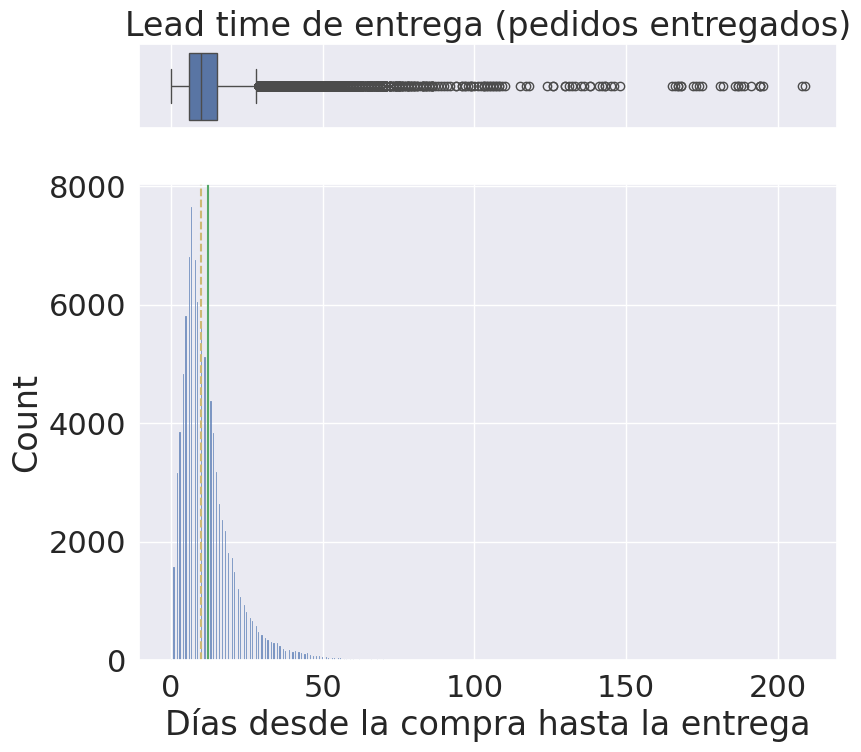

In [ ]:
histogram_boxplot(
    orders_analytical.loc[entregado, 'lead_time_dias'].dropna(),
    xlabel='Días desde la compra hasta la entrega',
    title='Lead time de entrega (pedidos entregados)'
)


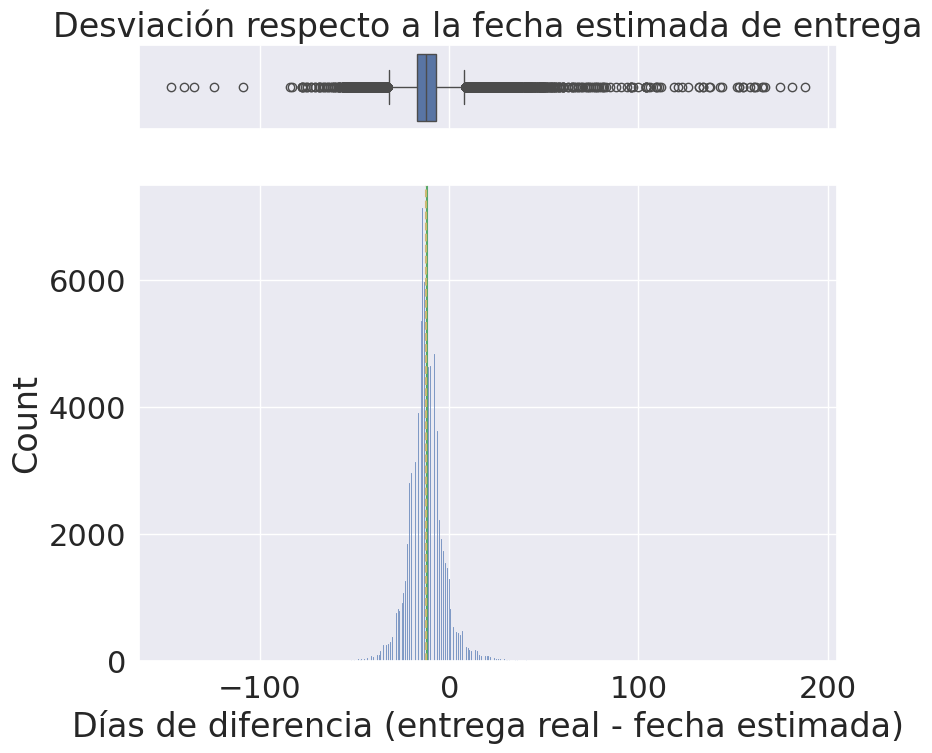

In [ ]:
histogram_boxplot(
    orders_analytical.loc[entregado, 'delta_entrega_dias'].dropna(),
    xlabel='Días de diferencia (entrega real - fecha estimada)',
    title='Desviación respecto a la fecha estimada de entrega'
)


In [ ]:
# Evolución mensual de la fecha estimada vs. la fecha real de entrega
entrega_mensual = (
    orders_analytical
    .loc[entregado]
    .assign(mes=lambda d: d['order_purchase_timestamp'].dt.to_period('M').astype(str))
    .groupby('mes')
    .agg(lead_time_medio=('lead_time_dias', 'mean'),
         delta_medio=('delta_entrega_dias', 'mean'))
    .reset_index()
)

fig = px.line(entrega_mensual, x='mes', y=['lead_time_medio', 'delta_medio'],
              title='Evolución mensual del lead time medio y de la desviación media sobre lo estimado')
fig.update_xaxes(tickangle=45)
fig.show()


- Tiempo Total de Entrega (lead_time_dias): Este gráfico ilustra el tiempo que transcurre desde que un cliente realiza un pedido hasta que lo recibe. Es un indicador fundamental de nuestra eficiencia logística. Nos permite comprender cuál es nuestro tiempo de entrega típico y si existen entregas excepcionalmente largas, que podrían señalar problemas en la cadena de suministro o con ciertos tipos de productos/ubicaciones. Desde una perspectiva de negocio, optimizar este tiempo es clave para mejorar la experiencia del cliente y nuestra competitividad en el mercado.

- Desviación de la Fecha Estimada de Entrega (delta_entrega_dias): Este indicador mide directamente nuestra capacidad para cumplir las promesas de entrega. Un valor negativo significa que el pedido se entregó antes de lo estimado (un factor que genera una experiencia positiva en el cliente), mientras que un valor positivo indica un retraso. El análisis muestra que la mayoría de las entregas se realizan antes o en la fecha estimada, lo cual es un punto fuerte. Sin embargo, la 'cola larga' de valores positivos (los retrasos) es donde reside el riesgo principal, ya que son estos incidentes, aunque sean una minoría, los que mayor insatisfacción generan. Identificar las causas raíz de estos retrasos es crítico.

- Evolución Mensual del Rendimiento de Entrega: Este gráfico nos permite observar cómo el tiempo medio total de entrega y la desviación media respecto a lo estimado varían a lo largo de los meses. Es esencial para detectar patrones estacionales, identificar si nuestro rendimiento de entrega está mejorando o empeorando con el tiempo, y reconocer posibles picos de demanda que podrían poner a prueba nuestra capacidad operativa. Esta información es vital para una planificación logística proactiva, la asignación eficiente de recursos y para establecer expectativas de entrega realistas para nuestros clientes durante todo el año.



###4.6.	Relación entre variables clave y satisfacción (adelanto visual)

Este apartado corresponde a la **fase a priori** del flujo de modelización adjuntado al proyecto (relaciones entre predictores y relaciones con la variable objetivo, contrastadas con análisis estadístico chi²/t-test/ANOVA antes de plantear cualquier modelo). Aquí se aplica esa misma lógica sobre `insatisfaccion` como adelanto visual y estadístico de la modelización del capítulo 6, distinguiendo entre predictores categóricos (test chi-cuadrado de independencia) y predictores numéricos (t-test de diferencia de medias entre satisfechos e insatisfechos).

In [ ]:
# Relación entre variables CATEGÓRICAS y satisfacción (test chi-cuadrado de independencia)
cat_vars = ['payment_type_principal', 'customer_region', 'cliente_recurrente']

for var in cat_vars:
    tabla = pd.crosstab(orders_analytical[var], orders_analytical['insatisfaccion'])
    chi2, p, dof, exp = stats.chi2_contingency(tabla)
    print(f"{var:25s} vs insatisfaccion  ->  chi2={chi2:8.2f}  p={p:.4g}  {'(significativo)' if p < 0.05 else '(no significativo)'}")


payment_type_principal    vs insatisfaccion  ->  chi2=   31.95  p=1.957e-06  (significativo)
customer_region           vs insatisfaccion  ->  chi2=  171.17  p=5.855e-36  (significativo)
cliente_recurrente        vs insatisfaccion  ->  chi2=    0.84  p=0.36  (no significativo)


In [ ]:
# Relación entre variables NUMÉRICAS y satisfacción (t-test de Welch entre grupos)
num_vars = ['lead_time_dias', 'delta_entrega_dias', 'total_price', 'total_freight', 'max_installments']

for var in num_vars:
    grupo0 = orders_analytical.loc[orders_analytical['insatisfaccion'] == 0, var].dropna()
    grupo1 = orders_analytical.loc[orders_analytical['insatisfaccion'] == 1, var].dropna()
    t, p = stats.ttest_ind(grupo0, grupo1, equal_var=False)
    print(f"{var:20s} media_satisfechos={grupo0.mean():8.2f}  media_insatisfechos={grupo1.mean():8.2f}  "
          f"t={t:7.2f}  p={p:.4g}  {'(significativo)' if p < 0.05 else '(no significativo)'}")


lead_time_dias       media_satisfechos=   10.69  media_insatisfechos=   17.41  t= -66.51  p=0  (significativo)
delta_entrega_dias   media_satisfechos=  -13.08  media_insatisfechos=   -7.34  t= -55.80  p=0  (significativo)
total_price          media_satisfechos=  134.44  media_insatisfechos=  149.31  t=  -8.35  p=6.946e-17  (significativo)
total_freight        media_satisfechos=   21.92  media_insatisfechos=   25.98  t= -20.85  p=7.39e-96  (significativo)
max_installments     media_satisfechos=    2.89  media_insatisfechos=    3.08  t=  -9.13  p=7.381e-20  (significativo)


In [ ]:
# Visualización: desviación de entrega según la valoración recibida
fig = px.box(
    orders_analytical.dropna(subset=['delta_entrega_dias', 'review_score']),
    x='review_score', y='delta_entrega_dias',
    title='Desviación respecto a la entrega estimada, según valoración (review_score)'
)
fig.show()


In [ ]:
# Matriz de correlación entre variables numéricas clave y review_score
num_cols = ['review_score', 'delta_entrega_dias', 'lead_time_dias',
            'total_price', 'total_freight', 'max_installments', 'n_items']

corr = orders_analytical[num_cols].corr()

fig = px.imshow(corr, text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                 title='Matriz de correlación — variables clave vs review_score')
fig.show()


Para identificar qué factores están relacionados con la insatisfacción del cliente, se han aplicado pruebas estadísticas de asociación y comparación de medias. Los resultados muestran que el tipo de pago y la región del cliente presentan una relación estadísticamente significativa con la insatisfacción. En cambio, ser un cliente recurrente no muestra una relación significativa, por lo que no se puede afirmar que la recurrencia del cliente esté asociada a una mayor o menor insatisfacción.

En las variables numéricas, sí se observan diferencias significativas entre clientes satisfechos e insatisfechos. Los clientes insatisfechos presentan un tiempo medio de entrega mayor (17,41 días frente a 10,69), lo que refuerza la importancia de los plazos de entrega en la experiencia del cliente. También presentan un delta de entrega menos favorable (-7,34 frente a -13,08 días), indicando que los pedidos de clientes satisfechos suelen entregarse con mayor margen respecto al plazo previsto.

Además, los clientes insatisfechos realizan, en promedio, pedidos de mayor importe (149,31 frente a 134,44) y soportan mayores costes de envío (25,98 frente a 21,92). También utilizan ligeramente más cuotas de pago (3,08 frente a 2,89). Aunque estas diferencias son estadísticamente significativas, su relevancia práctica debe interpretarse junto con el resto de factores.

En conjunto, los resultados apuntan a que los tiempos y condiciones de entrega son algunos de los factores más claramente relacionados con la insatisfacción, mientras que variables como la región y el tipo de pago también presentan diferencias que conviene considerar en análisis posteriores.

##5. Feature engineering (previo a modelización)

In [ ]:
# Función para calcular VCramer (dos nominales de entrada!)
def cramers_v(var1, varObj):
    if not var1.dtypes.name == 'category':
        #bins = min(5,var1.value_counts().count())
        var1 = pd.cut(var1, bins = 5)
    if not varObj.dtypes.name == 'category': #np.issubdtype(varObj, np.number):
        #bins = min(5,varObj.value_counts().count())
        varObj = pd.cut(varObj, bins = 5)

    data = pd.crosstab(var1, varObj).values
    vCramer = stats.contingency.association(data, method = 'cramer')
    return vCramer

In [ ]:
#Recobramos las variables objetivo como categóricas para poder utilizar Cramer
insatisfaccion = orders_analytical['insatisfaccion'].astype('category')
retraso = orders_analytical['retraso'].astype('category')

#Primero creamos un imput para poder analizar los predictores
imput = orders_analytical.drop(['retraso', 'insatisfaccion'],axis=1)

#Eliminamos las variables que pueden afecar a la calidad de los datos, creadas para investigación previa.
#Estas variables introducen data leakage
imput = imput.drop(['lead_time_dias', 'delta_entrega_dias', 'cliente_recurrente', 'cliente_recurrente'],axis=1)

#Para hacer un análisis sin ruido creamos dos variables aleatorias, para saber qué variables son relevantes y cuáles no
imput['aleatorio'] = np.random.uniform(0, 1, size=imput.shape[0])
imput['aleatorio2'] = np.random.uniform(0, 1, size=imput.shape[0])
imput['customer_region'] = imput['customer_region'].astype('category')

In [ ]:
imput.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 38 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  category      
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99295 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97660 non-null  datetime64[ns]
 6   order_delivered_customer_date  96484 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  string        
 10  customer_city                  99441 non-null  object        
 11  customer_state 

###5.1 Adicional, Análisis de variables para modelización



In [ ]:
#Numericas

num_vars = [col for col in num_vars if col in imput.columns]

# 1. VARIABLES CATEGÓRICAS

categorical_features = imput.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

for col in categorical_features:
    print(
        f"{col:35} "
        f"{imput[col].nunique():6} categorías"
    )

# 2. CRAMER
cramer_candidates = categorical_features + ['aleatorio', 'aleatorio2']

for col in categorical_features:
    if imput[col].dtypes.name != 'category':
        imput[col] = imput[col].astype('category')

cramer_results = pd.DataFrame(
    imput[cramer_candidates].apply(lambda x: cramers_v(x, insatisfaccion)),
    columns=['VCramer']
).sort_values('VCramer', ascending=False)

print(cramer_results)

umbral_ruido = cramer_results.loc[['aleatorio', 'aleatorio2'], 'VCramer'].max()
print(f"\nUmbral de ruido (max entre aleatorio/aleatorio2): {umbral_ruido:.4f}")

no_informativas = cramer_results[cramer_results['VCramer'] <= umbral_ruido].index.tolist()
print(f"Variables categóricas no informativas (por debajo del ruido): {no_informativas}")

# 3. CARDINALIDAD

cardinality = (
    imput[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

print(cardinality)

# 4. VARIABLES CONSTANTES

constant_vars = [
    col
    for col in num_vars
    if imput[col].nunique() <= 1
]

print("Variables constantes:")
print(constant_vars)

# 5. RESUMEN

print("=" * 60)
print("RESUMEN")
print("=" * 60)

print("Observaciones:", len(imput))
print("Variables:", imput.shape[1])

print("\nTop 10 por correlación (Pearson, numéricas):")
print(corr.head(10))

print("\nTop 10 categóricas por Cramér's V:")
print(cramer_results.head(10))

order_id                             99441 categorías
customer_id                          99441 categorías
order_status                             8 categorías
customer_unique_id                   96096 categorías
customer_zip_code_prefix             14994 categorías
customer_city                         4119 categorías
customer_state                          27 categorías
customer_region                          5 categorías
categoria_principal                     74 categorías
payment_type_principal                   5 categorías
review_score                             5 categorías
city_mean                             4057 categorías
state_mean                              27 categorías
order_purchase_month                    25 categorías
order_purchase_day                       7 categorías
                           VCramer
order_id                  1.000000
customer_id               1.000000
review_score              1.000000
customer_unique_id        0.990499
customer_zip_co

###5.1 Variables relevantes en la predicción de insatisfacción del cliente

En este listado no se incluye: review_score (es lo que se pretende predecir más adelante) ni las variables de creación de la valoración, pues son posteriores al hecho que se quiere predecir en el apartado 6: review_creation_date, review_answer_timestamp'

In [ ]:
# Establecemos las variables que queremos comprobar como potenciales predictores.

predictores_insat = ['order_status', 'customer_region','total_price','order_approved_at', 'order_delivered_customer_date',
               'order_estimated_delivery_date', 'order_delivered_carrier_date', 'total_freight', 'n_items','n_sellers_distintos',
               'peso_total_g', 'total_payment','n_pagos', 'max_installments', 'payment_type_principal', 'lat_mean', 'lng_mean',
               'dias_aprobacion', 'order_purchase_hour','ticket_medio_item', 'pct_flete',
               'aleatorio', 'aleatorio2',]


In [ ]:
# Ranking frente a insatisfaccion
TCramer_insat = pd.DataFrame(imput[predictores_insat].apply(lambda x: cramers_v(x, insatisfaccion)),
    columns=['VCramer'])

px.bar(TCramer_insat, x=TCramer_insat.VCramer,
       height=900,
       title='Importancia de variables frente a Insatisfaccion del cliente').update_yaxes(categoryorder="total ascending")

In [ ]:
# Listado de variables ordenadas por importancia
print("Variables ordenadas por V de Cramér:\n")

for variable, valor in TCramer_insat.sort_values(
    'VCramer', ascending=False
)['VCramer'].items():
    print(f"- {variable}: V de Cramér = {valor:.4f}")

Variables ordenadas por V de Cramér:

- order_status: V de Cramér = 0.2505
- n_sellers_distintos: V de Cramér = 0.1040
- order_approved_at: V de Cramér = 0.0946
- order_delivered_carrier_date: V de Cramér = 0.0838
- order_delivered_customer_date: V de Cramér = 0.0744
- order_estimated_delivery_date: V de Cramér = 0.0682
- customer_region: V de Cramér = 0.0415
- lat_mean: V de Cramér = 0.0354
- n_items: V de Cramér = 0.0289
- max_installments: V de Cramér = 0.0270
- lng_mean: V de Cramér = 0.0269
- peso_total_g: V de Cramér = 0.0228
- pct_flete: V de Cramér = 0.0221
- payment_type_principal: V de Cramér = 0.0179
- order_purchase_hour: V de Cramér = 0.0127
- total_freight: V de Cramér = 0.0125
- ticket_medio_item: V de Cramér = 0.0099
- total_payment: V de Cramér = 0.0085
- dias_aprobacion: V de Cramér = 0.0083
- total_price: V de Cramér = 0.0075
- aleatorio2: V de Cramér = 0.0066
- n_pagos: V de Cramér = 0.0036
- aleatorio: V de Cramér = 0.0030


###5.2 Variables relevantes en la predicción de retraso en la entrega

In [ ]:
# Ranking frente a retraso
predictores_retraso = ['customer_region','total_price','order_approved_at', 'order_delivered_carrier_date', 'total_freight', 'n_items',
                       'n_sellers_distintos', 'peso_total_g', 'total_payment','n_pagos', 'max_installments', 'payment_type_principal',
                       'lat_mean', 'lng_mean', 'order_purchase_hour','ticket_medio_item', 'pct_flete','aleatorio', 'aleatorio2',]

TCramer_retraso = pd.DataFrame(imput[predictores_retraso].apply(lambda x: cramers_v(x, retraso)), columns=['VCramer']
)
px.bar(TCramer_retraso, x=TCramer_retraso.VCramer,
       height=900,
       title='Importancia de variables frente a retraso en la entrega'
       ).update_yaxes(categoryorder="total ascending")

In [ ]:
# Listado 2 de variables ordenadas por importancia
print("Variables ordenadas por V de Cramér:\n")

for variable, valor in TCramer_retraso.sort_values(
    'VCramer', ascending=False
)['VCramer'].items():
    print(f"- {variable}: V de Cramér = {valor:.4f}")

Variables ordenadas por V de Cramér:

- order_approved_at: V de Cramér = 0.1460
- order_delivered_carrier_date: V de Cramér = 0.1197
- customer_region: V de Cramér = 0.0745
- lat_mean: V de Cramér = 0.0569
- lng_mean: V de Cramér = 0.0356
- n_sellers_distintos: V de Cramér = 0.0284
- ticket_medio_item: V de Cramér = 0.0147
- payment_type_principal: V de Cramér = 0.0147
- order_purchase_hour: V de Cramér = 0.0120
- max_installments: V de Cramér = 0.0086
- pct_flete: V de Cramér = 0.0076
- n_items: V de Cramér = 0.0070
- peso_total_g: V de Cramér = 0.0055
- total_price: V de Cramér = 0.0052
- aleatorio: V de Cramér = 0.0050
- total_payment: V de Cramér = 0.0043
- aleatorio2: V de Cramér = 0.0041
- n_pagos: V de Cramér = 0.0033
- total_freight: V de Cramér = 0.0017


###5.3.	Tratamiento de outliers, encoding y normalización

Para el próximo paso (modelización predictiva) antes de nada, cogemos aquellas variables numéricas con gran asimetría y le aplicamos una normalización con la fórmula de gestiona_outliers del punto 3, que dejamos pendiente para no sacar en los pasos siguientes conclusiones erróneas.

In [ ]:
# Comprobamos primero en modo 'check' antes de decidir el tratamiento de dias_aprobacion
lower, upper, total = gestiona_outliers(imput['dias_aprobacion'], clas='check')
print(f"dias_aprobacion -> % marcado como outlier: {total:.2f}%")

dias_aprobacion
dias_aprobacion -> % marcado como outlier: 17.54%


In [ ]:
var_num = ['total_price', 'total_freight', 'dias_aprobacion']
for col in var_num:
    imput[col] = gestiona_outliers(imput[col], clas='winsor')

imput['payment_type_principal'] = imput['payment_type_principal'].astype('category')
imput['customer_region'] = imput['customer_region'].astype('category')

total_price
total_freight
dias_aprobacion


##6. Modelización predictiva

###6.1.	Planteamiento del problema (Predicción de insatisfacción del cliente / Predicción de riesgo de retraso en la entrega)
###6.2.	Comparativa de modelos (Logistic Regression, Random Forest, XGBoost/LightGBM)
###6.3.	Comparativa de métricas (Accuracy, ROC-AUC, matriz de confusión) y métricas elegidas


###6.1.	Planteamiento del problema (Predicción de insatisfacción del cliente / Predicción de riesgo de retraso en la entrega)

In [ ]:
# fórmula de modelo completo OLS
def ols_formula(df, dependent_var, *excluded_cols):
    df_columns = list(df.columns.values)
    df_columns.remove(dependent_var)
    for col in excluded_cols:
        df_columns.remove(col)
    return dependent_var + ' ~ ' + ' + '.join(df_columns)

In [ ]:
# Función para calcular VIF
def vif_modelo(formula,data):

    # Matriz explícita de diseño y var objetivo por separado (extensión a dummies incluida)
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")

    # Calcula VIF para las variables
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    # Elimina la pendiente y ordena
    vif_tabla = vif_data[vif_data['feature'] != 'Intercept'].sort_values(by='VIF', ascending=False)

    return vif_tabla

####Insatisfacción
Primero hacemos Training-test split, usamos la fórmula OLS para la regresión lineal (primero de los modelos)

In [ ]:
predictores_insat_red = ['customer_region', 'n_sellers_distintos', 'pct_flete',
                         'ticket_medio_item', 'dias_aprobacion','order_purchase_hour'
]


In [ ]:
# 1. Training-test split
X_train_insat, X_test_insat, y_train_insat, y_test_insat = train_test_split(
    imput[predictores_insat_red], insatisfaccion, test_size=0.2, random_state=42
)

print('Training dataset shape Bin:', X_train_insat.shape, y_train_insat.shape)
print(y_train_insat.value_counts(normalize=True))

Training dataset shape Bin: (79552, 6) (79552,)
insatisfaccion
0    0.773205
1    0.226795
Name: proportion, dtype: float64


In [ ]:
# 2. Dataset de training con la objetivo dentro
data_train_insat = X_train_insat.copy().dropna()
data_train_insat['insatisfaccion'] = y_train_insat.loc[data_train_insat.index].astype('int64')

del X_train_insat, X_test_insat
gc.collect()

619

In [ ]:
# Aplicamos a fórmula de modelo reducido
form_insat = ols_formula(data_train_insat, 'insatisfaccion')
form_insat

'insatisfaccion ~ customer_region + n_sellers_distintos + pct_flete + ticket_medio_item + dias_aprobacion + order_purchase_hour'

In [ ]:
# Ajusto regresión de ejemplo
modelo_insat = logit(form_insat, data=data_train_insat).fit()
print(modelo_insat.summary())

Optimization terminated successfully.
         Current function value: 0.523554
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:         insatisfaccion   No. Observations:                78941
Model:                          Logit   Df Residuals:                    78931
Method:                           MLE   Df Model:                            9
Date:                Sat, 12 Sep 2026   Pseudo R-squ.:                 0.01110
Time:                        15:11:11   Log-Likelihood:                -41330.
converged:                       True   LL-Null:                       -41794.
Covariance Type:            nonrobust   LLR p-value:                7.000e-194
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -3.0471      0.080    -38.162      0.000   

In [ ]:
form_insat = modelo_insat.model.formula
tabla_vif = vif_modelo(form_insat, data_train_insat)
tabla_vif

,feature,VIF
3,customer_region[T.Sudeste],4.046852
4,customer_region[T.Sur],2.961244
1,customer_region[T.Nordeste],2.390191
6,pct_flete,1.313563
2,customer_region[T.Norte],1.300402
7,ticket_medio_item,1.272719
8,dias_aprobacion,1.004012
5,n_sellers_distintos,1.000572
9,order_purchase_hour,1.000477


####Retraso
Primero hacemos Training-test split, usamos la fórmula OLS para la regresión lineal (primero de los modelos)

In [ ]:
predictores_retraso_red = [
    'customer_region',
    'n_items', 'n_pagos', 'max_installments', 'peso_total_g',
    'order_purchase_hour', 'ticket_medio_item', 'pct_flete'

]

In [ ]:
# 1. Training-test split — SOLO pedidos entregados
entregado_mask = imput['order_status'] == 'delivered'

X_train_retraso, X_test_retraso, y_train_retraso, y_test_retraso = train_test_split(
    imput.loc[entregado_mask, predictores_retraso_red],
    retraso.loc[entregado_mask],
    test_size=0.2, random_state=42
)

print('Training dataset shape Bin:', X_train_retraso.shape, y_train_retraso.shape)
print(y_train_retraso.value_counts(normalize=True))

Training dataset shape Bin: (77182, 8) (77182,)
retraso
0.0    0.918129
1.0    0.081871
Name: proportion, dtype: float64


In [ ]:
# 2. Dataset de training con la objetivo dentro
data_train_retraso = X_train_retraso.copy().dropna()
data_train_retraso['retraso'] = y_train_retraso.loc[data_train_retraso.index].astype('int64')

del X_train_retraso, X_test_retraso
gc.collect()

0

In [ ]:
# Aplicamos a fórmula de modelo reducido
form_retraso = ols_formula(data_train_retraso, 'retraso')
form_retraso

'retraso ~ customer_region + n_items + n_pagos + max_installments + peso_total_g + order_purchase_hour + ticket_medio_item + pct_flete'

In [ ]:
# Ajusto regresión de ejemplo
modelo_retraso = logit(form_retraso, data=data_train_retraso).fit()
print(modelo_retraso.summary())

Optimization terminated successfully.
         Current function value: 0.280675
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                retraso   No. Observations:                77181
Model:                          Logit   Df Residuals:                    77169
Method:                           MLE   Df Model:                           11
Date:                Sat, 12 Sep 2026   Pseudo R-squ.:                0.009224
Time:                        15:11:13   Log-Likelihood:                -21663.
converged:                       True   LL-Null:                       -21864.
Covariance Type:            nonrobust   LLR p-value:                 1.184e-79
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -2.3229      0.092    -25.188      0.000   

In [ ]:
form_retraso = modelo_retraso.model.formula
tabla_vif = vif_modelo(form_retraso, data_train_retraso)
tabla_vif

,feature,VIF
3,customer_region[T.Sudeste],4.033556
4,customer_region[T.Sur],2.961338
1,customer_region[T.Nordeste],2.378965
10,ticket_medio_item,1.424071
11,pct_flete,1.348749
2,customer_region[T.Norte],1.303832
8,peso_total_g,1.167177
7,max_installments,1.166579
5,n_items,1.081354
6,n_pagos,1.002698


####Comparativa de modelos

In [ ]:
imput.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 38 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  category      
 1   customer_id                    99441 non-null  category      
 2   order_status                   99441 non-null  category      
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99295 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97660 non-null  datetime64[ns]
 6   order_delivered_customer_date  96484 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  category      
 9   customer_zip_code_prefix       99441 non-null  category      
 10  customer_city                  99441 non-null  category      
 11  customer_state 

In [ ]:
# RANDOM FOREST - INSATISFACCIÓN
# Variables predictoras
X = imput[predictores_insat_red].copy()
y = insatisfaccion.copy()

# Convertimos variables categóricas a dummies
X = pd.get_dummies(X, columns=['customer_region'], drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Random Forest modificado poco a poco
rf_insat = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
    )

# Entrenamiento
rf_insat.fit(X_train, y_train)

# Predicción
y_pred = rf_insat.predict(X_test)
y_prob = rf_insat.predict_proba(X_test)[:, 1]

# Evaluación
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6987782191160943
ROC-AUC: 0.558869028373287

Matriz de confusión:
[[12786  2577]
 [ 3414  1112]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81     15363
           1       0.30      0.25      0.27      4526

    accuracy                           0.70     19889
   macro avg       0.55      0.54      0.54     19889
weighted avg       0.68      0.70      0.69     19889



In [ ]:
# RANDOM FOREST - RETRASO
# Solo pedidos entregados
entregado_mask = imput['order_status'] == 'delivered'

# Variables predictoras y target
X = imput.loc[entregado_mask, predictores_retraso_red].copy()
y = retraso.loc[entregado_mask].copy()

# Convertimos la variable categórica a dummies
X = pd.get_dummies(X, columns=['customer_region'], drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training dataset shape:', X_train.shape, y_train.shape)
print(y_train.value_counts(normalize=True))

# Random Forest modificado poco a poco
rf_retraso = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
    )

# Entrenamiento
rf_retraso.fit(X_train, y_train)

# Predicción
y_pred = rf_retraso.predict(X_test)
y_prob = rf_retraso.predict_proba(X_test)[:, 1]

# Evaluación
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training dataset shape: (77182, 11) (77182,)
retraso
0.0    0.91888
1.0    0.08112
Name: proportion, dtype: float64
Accuracy: 0.8499170812603648
ROC-AUC: 0.5627177216921033

Matriz de confusión:
[[16146  1585]
 [ 1311   254]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.91      0.92     17731
         1.0       0.14      0.16      0.15      1565

    accuracy                           0.85     19296
   macro avg       0.53      0.54      0.53     19296
weighted avg       0.86      0.85      0.86     19296



### XGBOOST - INSATISFACCIÓN


In [ ]:
# Variables predictoras y target
X = imput[predictores_insat_red].copy()
y = insatisfaccion.copy()

# Convertimos variables categóricas a dummies
X = pd.get_dummies(X, columns=['customer_region'], drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training dataset shape:', X_train.shape, y_train.shape)
print(y_train.value_counts(normalize=True))

peso_insat = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost modificado poco a poco
xgb_insat = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='aucpr',
 scale_pos_weight=peso_insat
    )

# Entrenamiento
xgb_insat.fit(X_train, y_train)

# Predicción
y_pred = xgb_insat.predict(X_test)
y_prob = xgb_insat.predict_proba(X_test)[:, 1]

# Evaluación
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training dataset shape: (79552, 9) (79552,)
insatisfaccion
0    0.772463
1    0.227537
Name: proportion, dtype: float64
Accuracy: 0.616421137312082
ROC-AUC: 0.5607671863369271

Matriz de confusión:
[[10405  4958]
 [ 2671  1855]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.68      0.73     15363
           1       0.27      0.41      0.33      4526

    accuracy                           0.62     19889
   macro avg       0.53      0.54      0.53     19889
weighted avg       0.68      0.62      0.64     19889



In [ ]:
#Como los resultados son malos, intentamos mejorar con SKFold y cross_val_score de Nuestras Funciones

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(xgb_insat, X, y, cv=cv, scoring='roc_auc')
print(f"ROC-AUC (CV): {scores.mean():.3f} ± {scores.std():.3f}")

ROC-AUC (CV): 0.578 ± 0.005


###XGBoost — Retraso

In [ ]:
# Solo pedidos entregados
entregado_mask = imput['order_status'] == 'delivered'

# Variables predictoras y target
X = imput.loc[entregado_mask, predictores_retraso_red].copy()
y = retraso.loc[entregado_mask].copy()

# Convertimos variables categóricas a dummies
X = pd.get_dummies(X, columns=['customer_region'], drop_first=True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training dataset shape:', X_train.shape, y_train.shape)
print(y_train.value_counts(normalize=True))

peso_retraso = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost modificado poco a poco
xgb_retraso = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='aucpr',
 scale_pos_weight=peso_retraso
)

# Entrenamiento
xgb_retraso.fit(X_train, y_train)

# Predicción
y_pred = xgb_retraso.predict(X_test)
y_prob = xgb_retraso.predict_proba(X_test)[:, 1]

# Evaluación
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training dataset shape: (77182, 11) (77182,)
retraso
0.0    0.91888
1.0    0.08112
Name: proportion, dtype: float64
Accuracy: 0.6921123548922057
ROC-AUC: 0.5730196909692109

Matriz de confusión:
[[12726  5005]
 [  936   629]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      0.72      0.81     17731
         1.0       0.11      0.40      0.17      1565

    accuracy                           0.69     19296
   macro avg       0.52      0.56      0.49     19296
weighted avg       0.86      0.69      0.76     19296



In [ ]:
#Como los resultados son malos, intentamos mejorar con SKFold y cross_val_score de Nuestras Funciones

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(xgb_retraso, X, y, cv=cv, scoring='roc_auc')
print(f"ROC-AUC (CV): {scores.mean():.3f} ± {scores.std():.3f}")

ROC-AUC (CV): 0.576 ± 0.006


## 7. Interpretabilidad y diagnóstico de causas

### 7.1. SHAP / Feature Importance

Los modelos de árboles (Random Forest, XGBoost) entrenados en el capítulo 6.2 mejoran el ajuste respecto a la regresión logística, pero pierden la lectura directa de coeficientes. Para recuperar esa interpretabilidad se aplica **SHAP** (*SHapley Additive exPlanations*) sobre los modelos XGBoost de ambos problemas (`xgb_insat`, `xgb_retraso`), por ser los de mayor complejidad y los que más lo necesitan.

Antes de calcular los valores SHAP, se reconstruyen explícitamente los conjuntos de test utilizados al entrenar `xgb_insat` y `xgb_retraso` en el capítulo 6.2 (misma selección de columnas, mismas *dummies* de `customer_region` y misma semilla `random_state=42`), ya que las variables genéricas `X_train`/`X_test` fueron sobrescritas por los bloques de código posteriores.

In [ ]:
# Insatisfacción
X_insat_shap = imput[predictores_insat_red].copy()
X_insat_shap = pd.get_dummies(X_insat_shap, columns=['customer_region'], drop_first=True)
y_insat_shap = insatisfaccion.copy()

X_train_insat_shap, X_test_insat_shap, y_train_insat_shap, y_test_insat_shap = train_test_split(
    X_insat_shap, y_insat_shap,
    test_size=0.2,
    random_state=42,
    stratify=y_insat_shap
)

# Retraso (solo pedidos entregados)
entregado_mask = imput['order_status'] == 'delivered'

X_retraso_shap = imput.loc[entregado_mask, predictores_retraso_red].copy()
X_retraso_shap = pd.get_dummies(X_retraso_shap, columns=['customer_region'], drop_first=True)
y_retraso_shap = retraso.loc[entregado_mask].copy()

X_train_retraso_shap, X_test_retraso_shap, y_train_retraso_shap, y_test_retraso_shap = train_test_split(
    X_retraso_shap, y_retraso_shap,
    test_size=0.2,
    random_state=42,
    stratify=y_retraso_shap
)

print('Test insatisfacción:', X_test_insat_shap.shape)
print('Test retraso:', X_test_retraso_shap.shape)

Test insatisfacción: (19889, 9)
Test retraso: (19296, 11)


#### SHAP — Insatisfacción

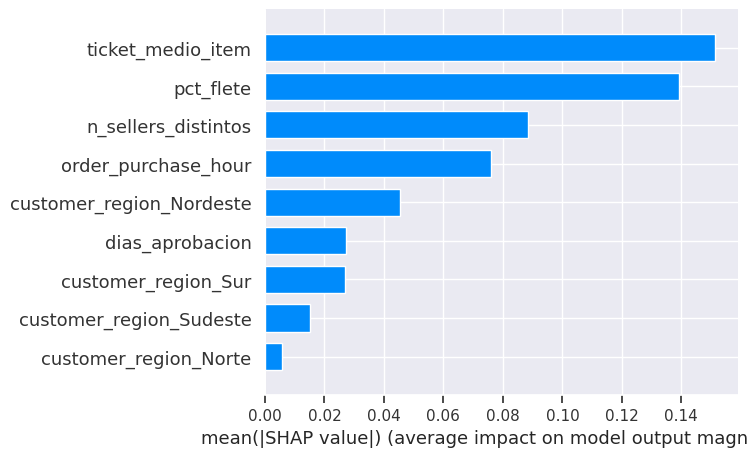

In [ ]:
# Explainer para modelos de árboles (rápido y exacto para XGBoost)
explainer_insat = shap.TreeExplainer(xgb_insat)
shap_values_insat = explainer_insat.shap_values(X_test_insat_shap)

# Importancia media por variables
shap.summary_plot(shap_values_insat, X_test_insat_shap, plot_type='bar', show=True)

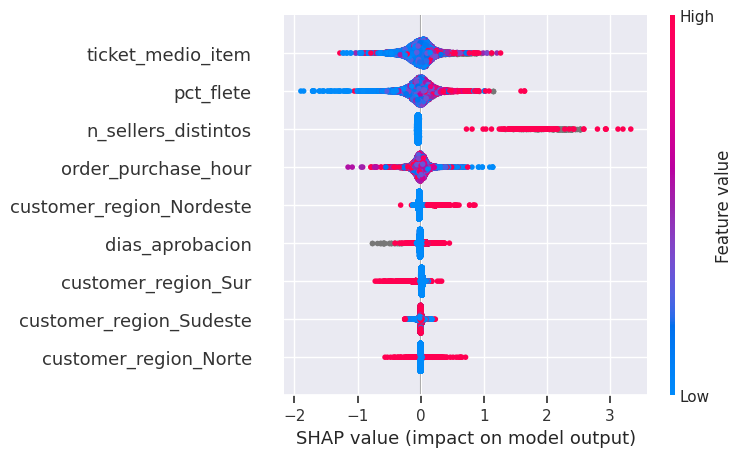

In [ ]:
# Distribución de impacto por variable (beeswarm): dirección y magnitud del efecto
shap.summary_plot(shap_values_insat, X_test_insat_shap, show=True)

#### SHAP — Retraso

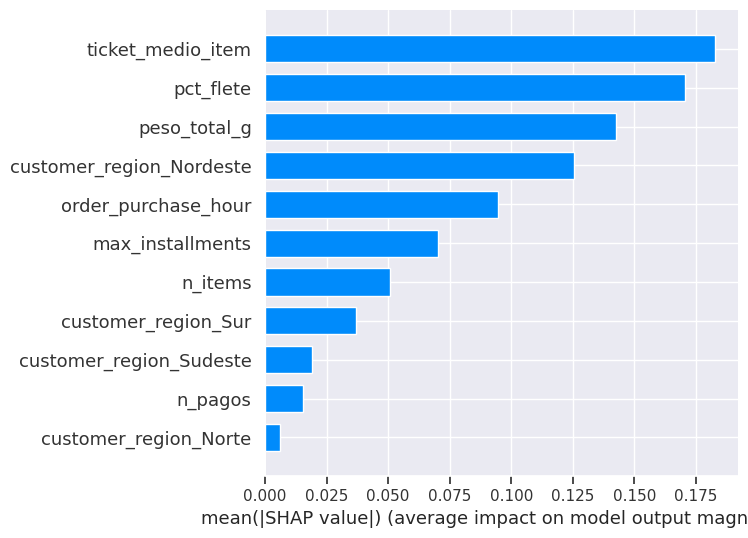

In [ ]:
explainer_retraso = shap.TreeExplainer(xgb_retraso)
shap_values_retraso = explainer_retraso.shap_values(X_test_retraso_shap)

shap.summary_plot(shap_values_retraso, X_test_retraso_shap, plot_type='bar', show=True)

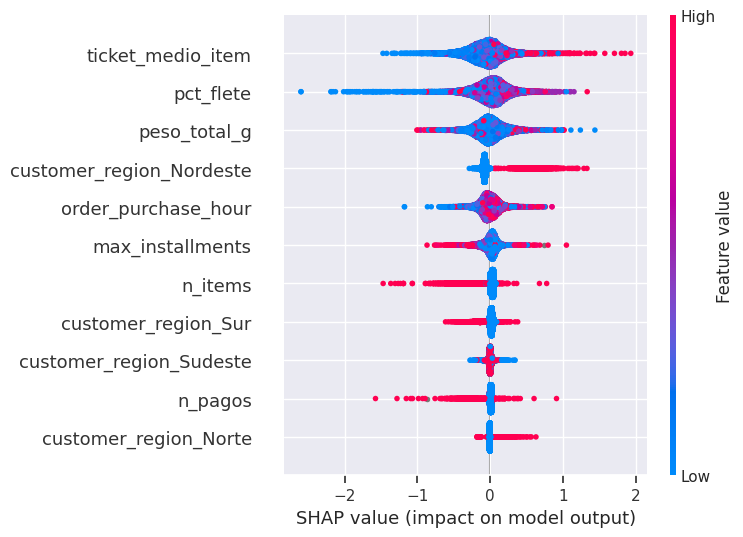

In [ ]:
shap.summary_plot(shap_values_retraso, X_test_retraso_shap, show=True)

### 7.2. Factores que más influyen en insatisfacción y retraso

Para poder documentar la comparación en la memoria (y contrastarla con los coeficientes del modelo logístico del capítulo 6.1 y con el ranking de V de Cramér del capítulo 5), se construye una tabla con la importancia media de cada variable (media de |SHAP|) para cada uno de los dos problemas.

In [ ]:
# Tabla de importancia SHAP — Insatisfacción
importancia_shap_insat = pd.DataFrame({
    'variable': X_test_insat_shap.columns,
    'shap_abs_medio': np.abs(shap_values_insat).mean(axis=0)
}).sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)

print('Importancia SHAP — Insatisfacción')
display(importancia_shap_insat)

# Tabla de importancia SHAP — Retraso
importancia_shap_retraso = pd.DataFrame({
    'variable': X_test_retraso_shap.columns,
    'shap_abs_medio': np.abs(shap_values_retraso).mean(axis=0)
}).sort_values('shap_abs_medio', ascending=False).reset_index(drop=True)

print('Importancia SHAP — Retraso')
display(importancia_shap_retraso)

Importancia SHAP — Insatisfacción


,variable,shap_abs_medio
0,ticket_medio_item,0.151467
1,pct_flete,0.139236
2,n_sellers_distintos,0.088416
3,order_purchase_hour,0.075852
4,customer_region_Nordeste,0.045553
5,dias_aprobacion,0.027303
6,customer_region_Sur,0.026897
7,customer_region_Sudeste,0.015166
8,customer_region_Norte,0.005667


Importancia SHAP — Retraso


,variable,shap_abs_medio
0,ticket_medio_item,0.182869
1,pct_flete,0.170511
2,peso_total_g,0.142588
3,customer_region_Nordeste,0.125396
4,order_purchase_hour,0.094498
5,max_installments,0.070045
6,n_items,0.050606
7,customer_region_Sur,0.036810
8,customer_region_Sudeste,0.019193
9,n_pagos,0.015349


## Próximos pasos

- Capitulo 8
- Capítulo 9:** para el análisis a nivel de item/categoría, partir de `order_items` original (no de esta tabla agregada a nivel de pedido)

## 8. Scoring y segmentación de actores — Problemas 3 y 4

### 8.1. Scoring de riesgo de vendedores

Para el problema 3 (vendedores de alto riesgo) se construye una **tarjeta de puntuación (*scorecard*)** siguiendo la metodología de tramificación óptima + WOE + regresión logística trabajada en la práctica de Scoring de Minería de Datos (`practica_scoring_P8.ipynb`), con la librería `optbinning`.

A diferencia de los problemas 1 y 2, aquí la unidad de análisis es el **vendedor**, no el pedido, por lo que primero hay que agregar los resultados de cada pedido (retraso, insatisfacción, cancelación) al nivel de `seller_id`, partiendo de `order_items_integrada` (única tabla que conserva `seller_id` junto con el resultado del pedido).

#### Construcción de la tabla de vendedores

In [ ]:
# Reutilizamos las variables objetivo ya definidas en el capítulo 3.3
pedido_targets = pd.DataFrame({
    'order_id': orders_analytical['order_id'],
    'order_status': orders_analytical['order_status'],
    'retraso': retraso.astype(float),
    'insatisfaccion': insatisfaccion.astype(int)
})
pedido_targets['cancelado'] = (pedido_targets['order_status'] == 'canceled').astype(int)

# order_items_integrada es la única tabla a nivel de línea que conserva seller_id
items_vendedor = order_items_integrada[['order_id', 'seller_id', 'price', 'freight_value',
                                          'seller_region']].merge(
    pedido_targets[['order_id', 'retraso', 'insatisfaccion', 'cancelado']],
    on='order_id', how='left'
)

print(items_vendedor.shape)
items_vendedor.head()

(112650, 8)


,order_id,seller_id,price,freight_value,seller_region,retraso,insatisfaccion,cancelado
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,58.90,13.29,Sudeste,0.0,0,0
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,Sudeste,0.0,0,0
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,199.00,17.87,Sudeste,0.0,0,0
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,Sudeste,0.0,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,199.90,18.14,Sur,0.0,0,0


In [ ]:
# Agregación a nivel de vendedor
vendedores = items_vendedor.groupby('seller_id').agg(
    n_pedidos=('order_id', 'nunique'),
    tasa_retraso=('retraso', 'mean'),
    tasa_insatisfaccion=('insatisfaccion', 'mean'),
    tasa_cancelacion=('cancelado', 'mean'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
    seller_region=('seller_region', lambda x: x.mode().iat[0] if not x.mode().empty else np.nan)
).reset_index()

print('Vendedores totales:', vendedores.shape[0])
vendedores['n_pedidos'].describe()

Vendedores totales: 3095


,n_pedidos
count,3095.000000
mean,32.313409
std,105.139763
min,1.000000
25%,2.000000
50%,6.000000
75%,21.500000
max,1854.000000


Como se documentó en el capítulo 2.3, los vendedores están muy concentrados (mediana de 8 pedidos, máximo de más de 2.000), por lo que puntuar a un vendedor con 1 o 2 pedidos totales (de los cuales uno haya ido mal) distorsionaría el modelo. Se aplica un **mínimo de pedidos** antes de entrar en el scoring.

In [ ]:
MIN_PEDIDOS = 5
vendedores_scoring = vendedores[vendedores['n_pedidos'] >= MIN_PEDIDOS].copy()
print(f"Vendedores con >= {MIN_PEDIDOS} pedidos: {vendedores_scoring.shape[0]} de {vendedores.shape[0]}")

# Índice de incidencias: combina las tres tasas de resultado negativo del pedido
vendedores_scoring['indice_incidencias'] = (
    vendedores_scoring['tasa_retraso'] +
    vendedores_scoring['tasa_insatisfaccion'] +
    vendedores_scoring['tasa_cancelacion']
) / 3

#Creamos un umbral de riesgo alto (0.75/1)
umbral_riesgo = vendedores_scoring['indice_incidencias'].quantile(0.75)
vendedores_scoring['alto_riesgo'] = (vendedores_scoring['indice_incidencias'] >= umbral_riesgo).astype(int)

print('Umbral (percentil 75):', round(umbral_riesgo, 4))
print(vendedores_scoring['alto_riesgo'].value_counts(normalize=True))

Vendedores con >= 5 pedidos: 1794 de 3095
Umbral (percentil 75): 0.135
alto_riesgo
0    0.749721
1    0.250279
Name: proportion, dtype: float64


#### División train/test

la partición train/test se hace antes de tramificar: la tramificación óptima y la selección de variables por IV se calculan únicamente sobre el conjunto de entrenamiento, y el conjunto de test se reserva para evaluar el modelo ya ajustado, evitando así sobreajuste en la propia fase de tramificación.

Como predictores del scorecard se usan variables descriptivas del perfil del vendedor (volumen, precio, flete, región)

In [ ]:
Y_completo = vendedores_scoring['alto_riesgo'].values
X_completo = vendedores_scoring[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

vend_train, vend_test = train_test_split(
    vendedores_scoring, stratify=vendedores_scoring['alto_riesgo'], test_size=0.25, random_state=321
)

Y = vend_train['alto_riesgo'].values
X = vend_train[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

Y_test = vend_test['alto_riesgo'].values
X_test = vend_test[['n_pedidos', 'precio_medio', 'flete_medio', 'seller_region']].copy()

print('Train:', X.shape, ' Tasa de evento:', Y.mean().round(3))
print('Test :', X_test.shape, ' Tasa de evento:', Y_test.mean().round(3))

Train: (1345, 4)  Tasa de evento: 0.251
Test : (449, 4)  Tasa de evento: 0.249


#### Tramificación óptima, WOE y selección de variables por IV



In [ ]:
list_variables = X.columns.tolist()
list_categorical = X.select_dtypes(include=['object', 'category']).columns.tolist()

selection_criteria = {"iv": {"min": 0.02}}

binning_process_vendedores = BinningProcess(
    min_bin_size=0.10,
    max_n_bins=5,
    categorical_variables=list_categorical,
    variable_names=list_variables,
    selection_criteria=selection_criteria
)

# El propio fit() devuelve el binning_process ya ajustado (patrón habitual de scikit-learn)
binning_process_vendedores.fit(X, Y)

binning_process_vendedores.summary().sort_values('iv', ascending=False)

,name,dtype,status,selected,n_bins,iv,js,gini,quality_score
0,n_pedidos,numerical,OPTIMAL,True,3,0.08687,0.010757,0.145159,0.251074
2,flete_medio,numerical,OPTIMAL,True,4,0.051947,0.00643,0.103531,0.162989
3,seller_region,categorical,OPTIMAL,True,2,0.030381,0.00378,0.06691,0.053133
1,precio_medio,numerical,OPTIMAL,True,5,0.024303,0.003015,0.060825,0.001323


#### Tarjeta de puntuación (Scorecard)

In [ ]:
estimator_vendedores = LogisticRegression(solver='lbfgs', penalty='l2')

pdo_0 = 40
scorecard_points_0 = 600
odds_0_B = 50

scorecard_vendedores = Scorecard(
    binning_process=binning_process_vendedores,
    estimator=estimator_vendedores,
    scaling_method="pdo_odds",
    scaling_method_params={"pdo": pdo_0, "odds": odds_0_B, "scorecard_points": scorecard_points_0}
)
scorecard_vendedores.fit(X, Y, show_digits=4)

scorecard_vendedores.table(style="detailed")

,Variable,Bin id,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS,Coefficient,Points
0,n_pedidos,0,"(-inf, 17.5000)",693,0.515242,489,204,0.294372,-0.221398,0.026617,3.320341e-03,-0.934939,97.362914
1,n_pedidos,1,"[17.5000, 52.5000)",353,0.262454,268,85,0.240793,0.052695,0.000719,8.988431e-05,-0.934939,112.151147
2,n_pedidos,2,"[52.5000, inf)",299,0.222305,251,48,0.160535,0.558611,0.059534,7.346458e-03,-0.934939,139.446993
3,n_pedidos,3,Special,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000e+00,-0.934939,109.308067
4,n_pedidos,4,Missing,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000e+00,-0.934939,109.308067
0,precio_medio,0,"(-inf, 69.1938)",438,0.325651,327,111,0.253425,-0.015211,0.000076,9.453441e-06,-0.663948,108.725275
1,precio_medio,1,"[69.1938, 87.0021)",144,0.107063,119,25,0.173611,0.464607,0.020383,2.525210e-03,-0.663948,127.109474
2,precio_medio,2,"[87.0021, 127.2451)",276,0.205204,205,71,0.257246,-0.035310,0.000258,3.226091e-05,-0.663948,107.955149
3,precio_medio,3,"[127.2451, 239.8927)",297,0.220818,220,77,0.259259,-0.045818,0.000469,5.860049e-05,-0.663948,107.552536
4,precio_medio,4,"[239.8927, inf)",190,0.141264,137,53,0.278947,-0.145952,0.003117,3.892964e-04,-0.663948,103.715940


#### Diagnóstico del modelo — conjunto de entrenamiento

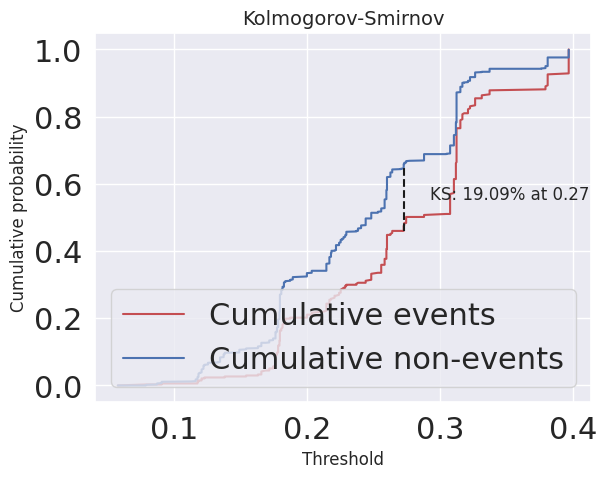

In [ ]:
Y_pred = scorecard_vendedores.predict_proba(X)[:, 1]

# Curva KS, para valorar visualmente la separación entre vendedores de riesgo y el resto
plot_ks(Y, Y_pred)

In [ ]:
# Punto de corte por F1 máximo
c = np.arange(0, 1, 0.01)
f1_scores = [f1_score(Y, np.multiply(Y_pred > c_, 1)) for c_ in c]
c_maxF1 = c[np.argmax(f1_scores)]
print('Punto de corte que maximiza F1:', round(c_maxF1, 2), '| F1 máximo:', round(np.max(f1_scores), 3))

# Punto de corte por índice de Youden
J = [balanced_accuracy_score(Y, np.multiply(Y_pred > c_, 1), adjusted=True) for c_ in c]
c_maxJ = c[np.argmax(J)]
print('Punto de corte que maximiza Youden:', round(c_maxJ, 2), '| J máximo:', round(np.max(J), 3))

# Como en la práctica de referencia, se toma como punto de partida la tasa base de evento
Prob_Corte = Y.mean()
print('Punto de corte adoptado (tasa base):', round(Prob_Corte, 2))

Punto de corte que maximiza F1: 0.25 | F1 máximo: 0.428
Punto de corte que maximiza Youden: 0.27 | J máximo: 0.184
Punto de corte adoptado (tasa base): 0.25


y_pronostico      0      1    All
alto_riesgo                      
0             0.386  0.364  0.749
1             0.083  0.167  0.251
All           0.469  0.531  1.000
Exactitud: 0.553

Sensibilidad (vendedores de riesgo bien detectados): 0.668
Especificidad (vendedores sin riesgo bien detectados): 0.515


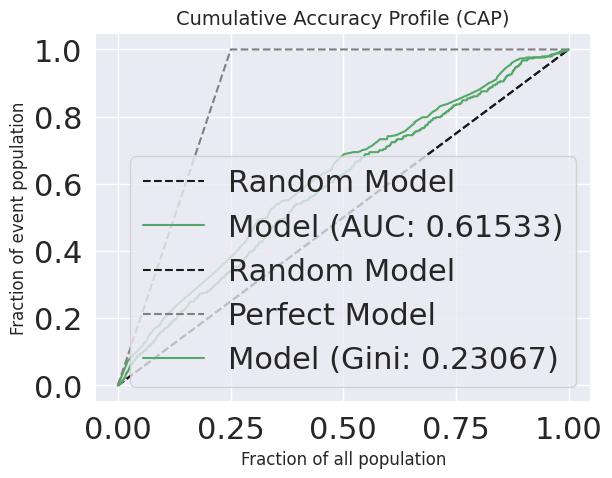

In [ ]:
# Matriz de confusión en entrenamiento con el punto de corte adoptado
vend_train = vend_train.copy()
vend_train['y_pronostico'] = np.multiply(Y_pred > Prob_Corte, 1)

tab = pd.crosstab(vend_train['alto_riesgo'], vend_train['y_pronostico'], margins=True, normalize='all').round(3)
print(tab)
print('Exactitud:', round(tab.iloc[1, 1] + tab.iloc[0, 0], 3))

tab_rec = pd.crosstab(vend_train['alto_riesgo'], vend_train['y_pronostico'], margins=True, normalize=0).round(3)
print('\nSensibilidad (vendedores de riesgo bien detectados):', tab_rec.iloc[1, 1])
print('Especificidad (vendedores sin riesgo bien detectados):', tab_rec.iloc[0, 0])

plot_auc_roc(Y, Y_pred)
plot_cap(Y, Y_pred)

#### Diagnóstico del modelo — conjunto de test (fuera de muestra)

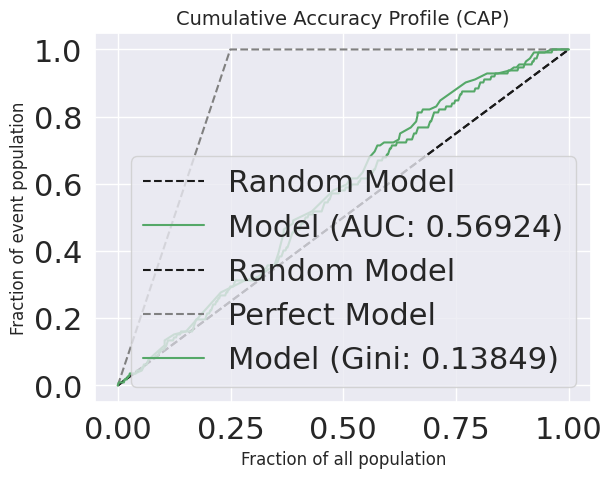

In [ ]:
Y_test_pred = scorecard_vendedores.predict_proba(X_test)[:, 1]

plot_auc_roc(Y_test, Y_test_pred)
plot_cap(Y_test, Y_test_pred)

In [ ]:
vend_test = vend_test.copy()
vend_test['y_pronostico'] = np.multiply(Y_test_pred > Prob_Corte, 1)

print('\nExactitud (test):\n', pd.crosstab(vend_test['alto_riesgo'], vend_test['y_pronostico'],
                                             margins=True, normalize='all').round(3))
print('\nf1-score (test):', round(f1_score(vend_test['alto_riesgo'], vend_test['y_pronostico']), 3))


Exactitud (test):
 y_pronostico      0      1    All
alto_riesgo                      
0             0.363  0.388  0.751
1             0.096  0.154  0.249
All           0.459  0.541  1.000

f1-score (test): 0.389


#### Puntuación final y salida orientada a negocio

Una vez validado el modelo en test, se aplica la tarjeta ya ajustada a **todos** los vendedores con volumen suficiente (train + test) para obtener la puntuación final que alimentará la recomendación del capítulo 11.

In [ ]:
vendedores_scoring['score_riesgo'] = scorecard_vendedores.score(X_completo)
vendedores_scoring['prob_alto_riesgo'] = scorecard_vendedores.predict_proba(X_completo)[:, 1]

print('Puntuación mínima:', round(vendedores_scoring['score_riesgo'].min(), 2))
print('Puntuación máxima:', round(vendedores_scoring['score_riesgo'].max(), 2))
print('Puntuación media :', round(vendedores_scoring['score_riesgo'].mean(), 2))

Puntuación mínima: 398.48
Puntuación máxima: 535.18
Puntuación media : 439.99


### 8.2. Segmentación de clientes (RFM + K-Means)

Para el problema 4 se segmenta a los clientes (`customer_unique_id`) por valor y comportamiento de compra. Como se documentó en el capítulo 2.3, la tasa de recompra real es muy baja (~3,5 % de clientes con más de un pedido), por lo que un RFM clásico —muy dependiente de la frecuencia histórica— generaría clusters poco discriminantes. Se combina por tanto la lógica RFM (recencia, frecuencia, monetario) con variables de comportamiento de compra (ticket medio, peso del flete, diversidad de categorías), siguiendo el mismo patrón de `scree_plot_kmeans` + `biplot` usado en las prácticas de Minería de Datos.

In [ ]:
fecha_referencia = orders_analytical['order_purchase_timestamp'].max()

customer_level = orders_analytical.groupby('customer_unique_id').agg(
    n_pedidos=('order_id', 'nunique'),
    valor_total=('total_payment', 'sum'),
    ticket_medio=('ticket_medio_item', 'mean'),
    pct_flete_medio=('pct_flete', 'mean'),
    n_categorias_distintas=('categoria_principal', 'nunique'),
    ultima_compra=('order_purchase_timestamp', 'max'),
).reset_index()

customer_level['recencia_dias'] = (fecha_referencia - customer_level['ultima_compra']).dt.days

print(customer_level.shape)
customer_level.describe()

(96096, 8)


,n_pedidos,valor_total,ticket_medio,pct_flete_medio,n_categorias_distintas,ultima_compra,recencia_dias
count,96096.000000,96096.000000,95420.000000,95420.000000,96096.000000,96096,96096.000000
mean,1.034809,166.592492,126.555747,0.208492,1.010823,2018-01-02 12:40:19.655864832,287.735691
min,1.000000,0.000000,0.850000,0.000000,0.000000,2016-09-04 21:15:19,0.000000
25%,1.000000,63.120000,42.900000,0.116622,1.000000,2017-09-15 09:04:17.249999872,163.000000
50%,1.000000,108.000000,79.445000,0.183256,1.000000,2018-01-21 19:39:16,268.000000
75%,1.000000,183.530000,139.900000,0.274677,1.000000,2018-05-06 20:14:49.750000128,397.000000
max,17.000000,13664.080000,6735.000000,0.955451,5.000000,2018-10-17 17:30:18,772.000000
std,0.214384,231.428332,191.751327,0.125019,0.165396,NaN,153.414676


In [ ]:
#Ajustamos la función de scree_plot_kmeans del archivo de nuestras funciones para evitar excesivos valores para la RAM
# Cremos función scree_plot_kmeans para buscar el número de clusters óptimo
# con 3 métricas usuales. Wss, silueta y % de varianza explicada
# Input: data = dataset en bruto (se escala dentro de la propia función)
#        n_max = número máximo de grupos a evaluar
# ==============================================================================

def scree_plot_kmeans(data,n_max):
  range_n_clusters = range(2, n_max)
  X_scaled = scale(data)
  inertias = []
  silhouette = []

  for n_clusters in range_n_clusters:
      modelo_kmeans = KMeans(
                          n_clusters   = n_clusters,
                          n_init       = 20,
                          random_state = 123
                      )
      modelo_kmeans.fit(X_scaled)
      cluster_labels = modelo_kmeans.fit_predict(X_scaled)
      inertias.append(modelo_kmeans.inertia_)
      silhouette.append(silhouette_score(X_scaled, cluster_labels, sample_size=5000, random_state=123)
      )
  fig, ax = plt.subplots(1, 3, figsize=(16, 6))
  ax[0].plot(range_n_clusters, inertias, marker='o')
  ax[0].set_title("Scree plot Varianza intra")
  ax[0].set_xlabel('Número clusters')
  ax[0].set_ylabel('Intra-cluster (inertia)')

  ax[1].plot(range_n_clusters, silhouette, marker='o')
  ax[1].set_title("Scree plot silhouette")
  ax[1].set_xlabel('Número clusters')
  ax[1].set_ylabel('Media índices silhouette');

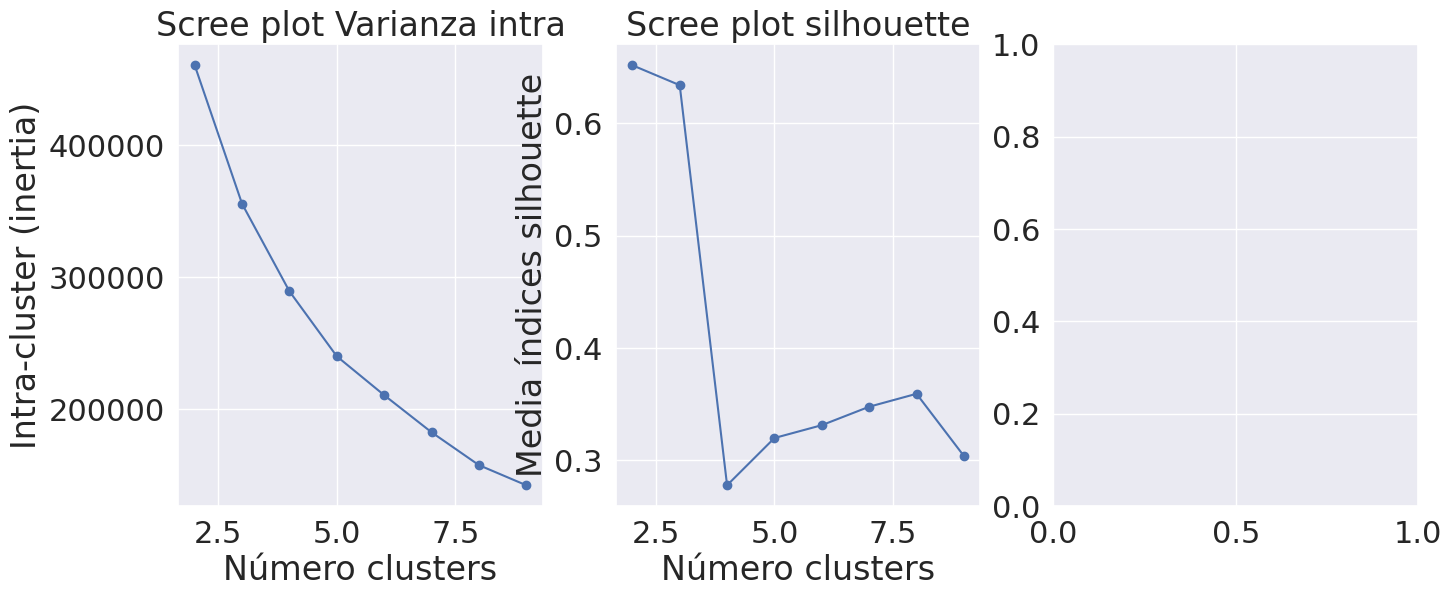

In [ ]:
rfm_vars = ['recencia_dias', 'n_pedidos', 'valor_total', 'ticket_medio',
            'pct_flete_medio', 'n_categorias_distintas']

X_rfm = customer_level[rfm_vars].fillna(0)

# Búsqueda del número óptimo de clusters (wss, silhouette, % varianza explicada)
scree_plot_kmeans(X_rfm, 10)

In [ ]:
k_optimo = 3

X_rfm_scaled = scale(X_rfm)

kmeans_clientes = KMeans(n_clusters=k_optimo, n_init=20, random_state=123)
customer_level['segmento'] = kmeans_clientes.fit_predict(X_rfm_scaled)

customer_level['segmento'].value_counts().sort_index()

,count
segmento,
0,90824
1,3588
2,1684


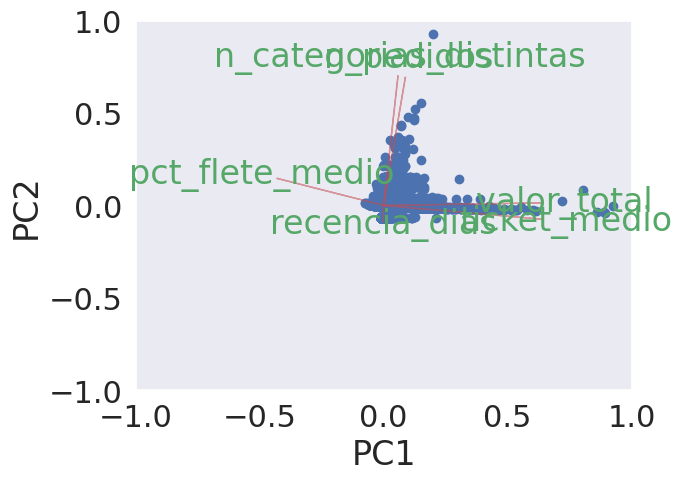

Varianza explicada por los 2 primeros componentes: 0.6367045133646049


In [ ]:
# Biplot: proyección de los clientes y de las variables RFM sobre los 2 primeros componentes
pca_clientes = PCA(n_components=2)
scores_clientes = pca_clientes.fit_transform(X_rfm_scaled)

biplot(scores_clientes[:, 0:2], np.transpose(pca_clientes.components_[0:2, :]), rfm_vars)
plt.show()

print('Varianza explicada por los 2 primeros componentes:',
      pca_clientes.explained_variance_ratio_.sum())

### 8.3. Caracterización de segmentos

Se describe cada segmento en términos de las variables RFM originales (sin escalar), para poder interpretarlo en lenguaje de negocio en el capítulo 11.

In [ ]:
resumen_segmentos = customer_level.groupby('segmento')[rfm_vars].mean().round(2)
resumen_segmentos['n_clientes'] = customer_level.groupby('segmento').size()
resumen_segmentos['pct_clientes'] = (resumen_segmentos['n_clientes'] / customer_level.shape[0] * 100).round(1)

resumen_segmentos

,recencia_dias,n_pedidos,valor_total,ticket_medio,pct_flete_medio,n_categorias_distintas,n_clientes,pct_clientes
segmento,,,,,,,,
0,288.35,1.01,131.21,98.48,0.21,0.99,90824,94.5
1,289.23,1.02,995.49,846.78,0.06,0.99,3588,3.7
2,251.60,2.20,308.67,105.35,0.22,2.02,1684,1.8


In [ ]:
# Visualización del perfil de cada segmento (valor medio del pedido, mismo estilo que en 6.2)
fig = px.bar(
    resumen_segmentos.reset_index(),
    x='segmento', y='valor_total',
    color='valor_total',
    template='plotly_white',
    color_continuous_scale='Blues',
    title='Valor total medio por segmento de cliente'
)
fig.show()

## 9. Diagnóstico territorial y de categoría — Problema 5

Este capítulo cierra el diagnóstico del problema 5 (dónde se concentran los retrasos y las incidencias), combinando los hallazgos geográficos del capítulo 4.2, el desempeño por categoría del capítulo 4.3, los factores explicativos de SHAP del capítulo 7 y el scoring de vendedores del capítulo 8.1. El objetivo no es repetir el EDA ya hecho, sino traducirlo en un **mapa de prioridades**: qué estados o regiones, qué categorías de producto y qué combinación de ambos concentran más riesgo, para orientar decisiones concretas de intervención logística en el capítulo 11.

### 9.1. Mapa de riesgo por estado/región

Se construye un índice de riesgo por estado que combina, a partes iguales, la tasa de insatisfacción y la tasa de retraso entre los pedidos entregados. Al ser ambas proporciones ya comparables (entre 0 y 1), se promedian directamente sin normalización adicional, evitando complejidad que no aporta valor. Junto al índice se calcula el **volumen de pedidos en riesgo** (índice × nº de pedidos), que pondera la tasa por el volumen para que un estado pequeño con tasa alta pero pocos pedidos no desplace a estados con mucho más impacto absoluto.

In [ ]:
# Riesgo por estado (granularidad fina, para el mapa)
geo_riesgo_estado = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_state')
    .agg(
        lat=('lat_mean', 'mean'),
        lng=('lng_mean', 'mean'),
        tasa_insatisfaccion=('insatisfaccion', 'mean'),
        tasa_retraso=('retraso', 'mean'),
        n_pedidos=('order_id', 'count'),
    )
    .reset_index()
)

geo_riesgo_estado['indice_riesgo'] = (
    geo_riesgo_estado['tasa_insatisfaccion'] + geo_riesgo_estado['tasa_retraso']
) / 2
geo_riesgo_estado['pedidos_en_riesgo'] = (
    geo_riesgo_estado['indice_riesgo'] * geo_riesgo_estado['n_pedidos']
).round(0)

geo_riesgo_estado.sort_values('indice_riesgo', ascending=False)

,customer_state,lat,lng,tasa_insatisfaccion,tasa_retraso,n_pedidos,indice_riesgo,pedidos_en_riesgo
1,AL,-9.641780,-36.038443,0.282116,0.239295,397,0.260705,104.0
9,MA,-3.574600,-44.707773,0.295676,0.196653,717,0.246165,176.0
21,RR,2.836692,-60.675324,0.317073,0.121951,41,0.219512,9.0
24,SE,-10.874020,-37.174953,0.274627,0.152239,335,0.213433,72.0
5,CE,-4.326283,-38.966348,0.270524,0.153245,1279,0.211884,271.0
4,BA,-13.024664,-39.461737,0.269042,0.140356,3256,0.204699,666.0
16,PI,-5.499493,-42.593359,0.245798,0.159664,476,0.202731,96.0
18,RJ,-22.752311,-43.173027,0.262753,0.134737,12350,0.198745,2454.0
13,PA,-2.383985,-49.078351,0.273784,0.123679,946,0.198732,188.0
7,ES,-20.146415,-40.492348,0.226065,0.122306,1995,0.174185,348.0


In [ ]:
fig = px.scatter_geo(
    geo_riesgo_estado, lat='lat', lon='lng', size='n_pedidos', color='indice_riesgo',
    hover_name='customer_state', scope='south america',
    color_continuous_scale='Blues', template='plotly_white',
    title='Índice de riesgo (insatisfacción + retraso) por estado'
)
fig.show()

top10_riesgo = geo_riesgo_estado.sort_values('pedidos_en_riesgo', ascending=False).head(10)
fig = px.bar(
    top10_riesgo, x='customer_state', y='pedidos_en_riesgo', color='indice_riesgo',
    template='plotly_white', color_continuous_scale='Blues',
    title='Top 10 estados por volumen de pedidos en riesgo'
)
fig.show()

### 9.2. Categorías con mayor incidencia

Se retoma `cat_summary` (calculada en el capítulo 4.3 a partir de `items_reviews`, a granularidad ítem) para construir el mismo tipo de índice de riesgo, ahora por categoría de producto, ponderado después por el volumen de ítems vendidos. Se mantiene el filtro de un mínimo de 30 ítems (`min_items`, ya definido en el capítulo 4.3) para que categorías anecdóticas no distorsionen el ranking.

In [ ]:
cat_relevante = cat_summary[cat_summary['n_items'] >= min_items].copy()

cat_relevante['indice_riesgo'] = (
    cat_relevante['tasa_insatisfaccion'] + cat_relevante['tasa_retraso']
) / 2
cat_relevante['impacto_potencial'] = (
    cat_relevante['indice_riesgo'] * cat_relevante['n_items']
).round(0)

top10_categorias = cat_relevante.sort_values('impacto_potencial', ascending=False).head(10)
top10_categorias[['n_items', 'tasa_insatisfaccion', 'tasa_retraso', 'indice_riesgo', 'impacto_potencial']]

,n_items,tasa_insatisfaccion,tasa_retraso,indice_riesgo,impacto_potencial
product_category_name_english,,,,,
bed_bath_table,11115,0.285290,0.083995,0.184643,2052.0
furniture_decor,8334,0.280898,0.084314,0.182606,1522.0
health_beauty,9670,0.214271,0.090544,0.152408,1474.0
computers_accessories,7827,0.266513,0.077708,0.172111,1347.0
sports_leisure,8641,0.218378,0.074131,0.146254,1264.0
housewares,6964,0.240953,0.064901,0.152927,1065.0
watches_gifts,5991,0.249708,0.082779,0.166243,996.0
telephony,4545,0.268647,0.083296,0.175971,800.0
garden_tools,4347,0.238325,0.079663,0.158994,691.0


In [ ]:
fig = px.bar(
    top10_categorias.reset_index(), x='product_category_name_english', y='impacto_potencial',
    color='indice_riesgo', template='plotly_white', color_continuous_scale='Blues',
    title='Top 10 categorías por impacto potencial (índice de riesgo × volumen)'
)
fig.update_xaxes(tickangle=45)
fig.show()

### 9.3. Priorización de intervención logística

Se cruzan las dos dimensiones anteriores con la información de vendedores del capítulo 8.1: por un lado, el riesgo del lado del cliente (por región); por otro, el riesgo del lado del vendedor (`indice_incidencias` de `vendedores_scoring`, agregado por región de vendedor); y por último, qué categorías concretas explican el riesgo dentro de la región más problemática. El resultado es una tabla de prioridades pensada para el equipo de logística: no basta con saber *que* una región concentra más retrasos, hace falta saber *qué* vender ahí con más cuidado y *qué vendedores* vigilar.

In [ ]:
# Riesgo por región (lado cliente), agregando directamente desde orders_analytical
riesgo_region_cliente = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_region')
    .agg(
        tasa_insatisfaccion=('insatisfaccion', 'mean'),
        tasa_retraso=('retraso', 'mean'),
        n_pedidos=('order_id', 'count'),
    )
)
riesgo_region_cliente['indice_riesgo_cliente'] = (
    riesgo_region_cliente['tasa_insatisfaccion'] + riesgo_region_cliente['tasa_retraso']
) / 2

# Riesgo por región (lado vendedor), reutilizando el scoring del capítulo 8.1
riesgo_region_vendedor = (
    vendedores_scoring.groupby('seller_region')['indice_incidencias'].mean()
    .rename('indice_riesgo_vendedor')
)

priorizacion_regional = riesgo_region_cliente.join(riesgo_region_vendedor)
priorizacion_regional['pedidos_en_riesgo'] = (
    priorizacion_regional['indice_riesgo_cliente'] * priorizacion_regional['n_pedidos']
).round(0)

priorizacion_regional.sort_values('pedidos_en_riesgo', ascending=False)

,tasa_insatisfaccion,tasa_retraso,n_pedidos,indice_riesgo_cliente,indice_riesgo_vendedor,pedidos_en_riesgo
customer_region,,,,,,
Sudeste,0.203248,0.074502,66200,0.138875,0.109585,9194.0
Sur,0.199001,0.070508,13814,0.134755,0.091389,1862.0
Nordeste,0.258072,0.143299,9044,0.200686,0.096057,1815.0
Centro-Oeste,0.215327,0.079659,5624,0.147493,0.085549,829.0
Norte,0.244989,0.097996,1796,0.171492,0.106481,308.0


In [ ]:
region_prioritaria = priorizacion_regional['pedidos_en_riesgo'].idxmax()
print('Región prioritaria:', region_prioritaria)

# Categorías que más pesan en la región prioritaria (granularidad ítem, con región del cliente)
items_geo_cat = order_items_integrada.merge(
    orders_analytical[['order_id', 'customer_region', 'insatisfaccion', 'retraso']],
    on='order_id', how='left'
)

cat_region_prioritaria = (
    items_geo_cat[items_geo_cat['customer_region'] == region_prioritaria]
    .groupby('product_category_name_english')
    .agg(n_items=('order_item_id', 'count'),
         tasa_insatisfaccion=('insatisfaccion', 'mean'),
         tasa_retraso=('retraso', 'mean'))
)
cat_region_prioritaria = cat_region_prioritaria[cat_region_prioritaria['n_items'] >= min_items]
cat_region_prioritaria['indice_riesgo'] = (
    cat_region_prioritaria['tasa_insatisfaccion'] + cat_region_prioritaria['tasa_retraso']
) / 2

cat_region_prioritaria.sort_values('indice_riesgo', ascending=False).head(10)

Región prioritaria: Sudeste


,n_items,tasa_insatisfaccion,tasa_retraso,indice_riesgo
product_category_name_english,,,,
diapers_and_hygiene,34,0.558824,0.030303,0.294563
office_furniture,1165,0.401717,0.082394,0.242055
audio,252,0.289683,0.108000,0.198841
home_confort,334,0.302395,0.087879,0.195137
party_supplies,31,0.322581,0.066667,0.194624
fixed_telephony,179,0.346369,0.035294,0.190831
fashio_female_clothing,38,0.342105,0.028571,0.185338
art,151,0.271523,0.098592,0.185057
furniture_living_room,381,0.293963,0.074667,0.184315


## 10. Productivización

Tras haber construido y validado diversos modelos predictivos para la insatisfacción del cliente y el retraso de entregas, damos pie al paso final: invocar estos modelos desde fuera. Siguiendo el patrón de Modelo serializado con FastAPI del módulo, productivizamos aquí el caso de predicción de retraso en entrega: dado un pedido nuevo, ¿va a llegar tarde o a tiempo?

### 10.1. Diseño de la función/API de scoring (input: nuevo pedido → output: predicción)

En primer lugar, partimos del modelo xgb_retraso, ya entrenado y validado en el capítulo 6.2, que serializamos con pickle, junto con el mismo esquema de columnas del entrenamiento.

Esto nos permite con cada nuevo pedido en formato texto, poder recontruir las variables de la misma forma que las tiene el modelo, para que pueda "entenderlas".

Este orden se recupera directamente del modelo (`get_booster().feature_names`), sin depender de que las variables genéricas de entrenamiento sigan disponibles en memoria.

In [ ]:
import pickle

# Reutilizamos el modelo xgb_retraso ya entrenado en el capítulo 6.2
with open('modelo_retraso.pkl', 'wb') as file:
    pickle.dump({
        'modelo': xgb_retraso,
        'columnas': xgb_retraso.get_booster().feature_names,
        'predictores_originales': predictores_retraso_red,
    }, file)

print("Modelo de retraso serializado: modelo_retraso.pkl")

Modelo de retraso serializado: modelo_retraso.pkl


### 10.2. Servicio de scoring en el momento de creación del pedido

Con el modelo ya serializado, se define la API siguiendo exactamente el mismo patrón del módulo: una app de FastAPI, una clase Pydantic con las variables de entrada del pedido y un endpoint `/predict` que aplica el modelo y devuelve el resultado.

El servicio se lanza en un hilo separado, tal como se hace en el ejemplo del curso, para que `uvicorn` quede escuchando peticiones sin bloquear la ejecución del notebook. La idea que, en el instante en que la plataforma registra un pedido nuevo, el sistema de creación de pedidos llame a este endpoint para decidir si conviene marcarlo para seguimiento proactivo, en línea con las recomendaciones de los capítulos 7.2, 8.1 y 9.3.

In [ ]:
# Creamos la puerta de entrada (API), la llamada al modelo para predecir retraso

app = FastAPI(
    title="API de Scoring de Retraso — TFM Olist",
    description="Predice si un pedido nuevo tendrá retraso en la entrega.",
    version="1.0.0",
    contact={
        "name": "Francisco Morales Reina",
        "email": "fran.moreina@gmail.com",
    },
)

# Cargar el modelo serializado
with open('modelo_retraso.pkl', 'rb') as file:
    artefacto_retraso = pickle.load(file)

REGIONES_VALIDAS = ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sur']

# Clase para la entrada de datos: las variables en crudo del pedido nuevo
class PedidoFeatures(BaseModel):
    customer_region: Literal['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sur']
    n_items: int
    n_pagos: int
    max_installments: int
    peso_total_g: float
    order_purchase_hour: int
    ticket_medio_item: float
    pct_flete: float


def _preparar_fila(pedido: PedidoFeatures) -> pd.DataFrame:
    fila = pd.DataFrame([pedido.model_dump()])
    region = fila.pop('customer_region').iloc[0]
    for r in REGIONES_VALIDAS:
        col = f'customer_region_{r}'
        if col in artefacto_retraso['columnas']:
            fila[col] = 1 if region == r else 0
    return fila.reindex(columns=artefacto_retraso['columnas'], fill_value=0)


# Endpoint para hacer predicciones
@app.post("/predict")
def predict(pedido: PedidoFeatures):
    X = _preparar_fila(pedido)
    prob = float(artefacto_retraso['modelo'].predict_proba(X)[:, 1][0])
    prediccion = int(prob >= 0.5)
    etiqueta = ['A tiempo', 'Con retraso'][prediccion]
    return {"prediccion": etiqueta, "probabilidad_retraso": round(prob, 4)}



def run():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="info")

# Correr en un hilo separado para evitar bloquear el notebook
thread = threading.Thread(target=run)
thread.start()

### 10.3. Demo (script, notebook interactivo)

Con el servicio ya levantado en el hilo anterior, se lanza una petición de prueba desde otra celda del notebook, exactamente como en el módulo: se construye el JSON de un pedido nuevo y se envía por `POST` con la librería `requests`.

In [ ]:
# Lanzo una petición al modelo de retraso

url = 'http://localhost:8000/predict'

data = {
    "customer_region": "Nordeste",
    "n_items": 3,
    "n_pagos": 1,
    "max_installments": 6,
    "peso_total_g": 8500,
    "order_purchase_hour": 22,
    "ticket_medio_item": 310.0,
    "pct_flete": 0.28
}

response = requests.post(url, json=data)
print(response.json())

INFO:     Started server process [825]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


INFO:     127.0.0.1:57020 - "POST /predict HTTP/1.1" 200 OK
{'prediccion': 'A tiempo', 'probabilidad_retraso': 0.1004}


Como demo interactiva adicional dentro del propio notebook, se ofrece también un pequeño formulario con `ipywidgets` que permite variar los datos del pedido y llamar al mismo endpoint `/predict` sin tener que editar el JSON a mano cada vez.

In [ ]:
w_region = widgets.Dropdown(options=REGIONES_VALIDAS, description='Región:')
w_flete = widgets.FloatSlider(value=0.15, min=0, max=1, step=0.01, description='% flete:')
w_ticket = widgets.FloatText(value=150.0, description='Ticket medio:')
w_hora = widgets.IntSlider(value=14, min=0, max=23, description='Hora compra:')
w_peso = widgets.FloatText(value=2000.0, description='Peso (g):')
boton = widgets.Button(description='Calcular riesgo de retraso')
salida = widgets.Output()


def calcular_riesgo(b):
    with salida:
        salida.clear_output()
        pedido = {
            'customer_region': w_region.value,
            'n_items': 1,
            'n_pagos': 1,
            'max_installments': 1,
            'peso_total_g': w_peso.value,
            'order_purchase_hour': w_hora.value,
            'ticket_medio_item': w_ticket.value,
            'pct_flete': w_flete.value,
        }
        resultado = requests.post(url, json=pedido).json()
        print(resultado)


boton.on_click(calcular_riesgo)
display(w_region, w_flete, w_ticket, w_hora, w_peso, boton, salida)

Dropdown(description='Región:', options=('Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sur'), value='Centro…

FloatSlider(value=0.15, description='% flete:', max=1.0, step=0.01)

FloatText(value=150.0, description='Ticket medio:')

IntSlider(value=14, description='Hora compra:', max=23)

FloatText(value=2000.0, description='Peso (g):')

Button(description='Calcular riesgo de retraso', style=ButtonStyle())

Output()